# KAMP X-ray 최종 분석 — 고유 이미지 512장 기준

**분석 대상: X-ray 이미지 512장 / 결함 bbox 1,163개 / 단일 클래스 `0: defect`**  

데이터 이해, 학습 설정 비교, 임계값 평가와 오류 분석은 동일한 최종 512장의 분할을 기준으로 연결한다.  

| 구분 | 이미지 | GT bbox | 분석 역할 |
|---|---:|---:|---|
| Train | 359 | 828 | 모델 학습 및 조건 기준 설정 |
| Val | 77 | 175 | 학습 설정 비교와 임계값 정책 선택 |
| Test | 76 | 160 | 고정 모델·정책 평가 및 오류 분석 |
| 합계 | 512 | 1,163 | 데이터 이해와 전체 구성 진단 |

이미지 비율과 객체 비율의 분모를 구분한다.  
Test의 FN 비율은 해당 조건의 Test GT 수를 분모로 계산하며 512장 전체의 오류율로 확대하지 않는다.  
전처리 선택과 shortcut 점검에 활용한 기존 **20장 PoC는 별도의 보조 실험**이다.  
그 결과를 512장 모델의 성능이나 shortcut 부재 증명으로 사용하지 않는다.  

목차: 1 프로젝트 개요 → 2 512장 데이터 이해 → 3 512장 전처리와 보조 비교 → 4 Shortcut 위험 및 보조 진단 → 5 512장 모델 비교 → 6 Val/Test 임계값 평가 → 7 Test 오류 분석 → 8 현장 활용 제안 → 9 최종 결론 → KAMP 평가항목 대응표 → 코드 및 재현성.  

노트북은 저장된 CSV·JSON·TXT·PNG·학습 로그를 읽어 표와 그림을 재생성한다.  
모델 학습이나 신규 추론은 실행하지 않는다.  
표시되는 PNG는 저장된 분석 그림이다.  
**상태 표기:** 검증됨=파일·계산의 일치 확인, 관찰됨=해당 표본의 결과, 제안됨=운영 아이디어, 미구현=아직 구현·운영 검증하지 않은 기능.  

**실행:** 이 제출 폴더에서 `requirements-notebook.txt`로 환경을 설치하고 전체 셀을 실행한다.  
실행 방법은 `README.md`, Jupyter 전체 실행 결과는 `verification.json`에 있다.


In [1]:
from pathlib import Path, PureWindowsPath
import hashlib
import json
import math
import sys
import numpy as np
import pandas as pd
from PIL import Image as PILImage
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string(index=False) if isinstance(value, pd.DataFrame) else value)

def find_project_root():
    cwd = Path.cwd().resolve()
    for candidate in (cwd, *cwd.parents):
        if (candidate/'outputs/yolo_512_telea/manifest.csv').exists() and (candidate/'train_yolo.py').exists() and (candidate/'requirements-notebook.txt').exists():
            return candidate
    raise FileNotFoundError('프로젝트 root 또는 하위 폴더에서 노트북을 실행하세요.')

ROOT = find_project_root()
pd.set_option('display.max_columns', 24)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', lambda v: f'{v:.6f}')
SOURCE_LEDGER = {}

def file_sha(path):
    digest = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            digest.update(block)
    return digest.hexdigest()

def source(relative):
    path = ROOT/relative
    if not path.is_file():
        raise FileNotFoundError(f'필수 저장 결과 누락: {relative}')
    SOURCE_LEDGER.setdefault(path.relative_to(ROOT).as_posix(), file_sha(path))
    return path

def load_json(relative):
    return json.loads(source(relative).read_text(encoding='utf-8-sig'))

def load_csv(relative):
    return pd.read_csv(source(relative), encoding='utf-8-sig')

def show_png(relative, caption=''):
    if caption:
        print(caption)
    path = source(relative)
    with PILImage.open(path) as image:
        display(image.copy())
    print(f'출처: {relative}')

def harmonized_f1(precision, recall):
    return 2*precision*recall/(precision+recall) if precision+recall else 0.0

manifest = load_csv('outputs/yolo_512_telea/manifest.csv')
assert len(manifest) == 512 and manifest['unique_id'].nunique() == 512
assert int(manifest['bbox_count'].sum()) == 1163
selected_ids_512 = set(manifest['unique_id'])
split_ids = {split: set(manifest.loc[manifest['split'] == split, 'unique_id'])
             for split in ('train', 'val', 'test')}
assert [len(split_ids[s]) for s in ('train', 'val', 'test')] == [359, 77, 76]
assert not any(split_ids[a] & split_ids[b] for a, b in [('train','val'), ('train','test'), ('val','test')])
assert set.union(*split_ids.values()) == selected_ids_512
clean_meta = load_csv('outputs/clean_512/metadata.csv')
split_summary = load_json('outputs/clean_512_split/split_summary.json')
restoration_summary = load_json('outputs/yolo_512_telea/restoration_summary.json')
threshold_summary = load_json('outputs/safety_threshold_policy/summary.json')
locked_policy = load_json('outputs/safety_threshold_policy/locked_policy.json')
error_summary = load_json('outputs/error_analysis/summary/summary.json')
assert restoration_summary['images'] == 512 and restoration_summary['bbox'] == 1163
assert threshold_summary['provenance']['image_count'] == len(split_ids['val']) + len(split_ids['test'])
assert threshold_summary['provenance']['model_sha256'] == error_summary['provenance']['model_sha256']
print('준비 완료: 저장 결과 읽기 전용 / 학습·추론 없음 / 모든 데이터 경로는 ROOT 기준')
display(pd.DataFrame([{'Python': sys.version.split()[0], 'pandas': pd.__version__,
                       'numpy': np.__version__, 'Notebook': 'KAMP_Xray_Final_Analysis.ipynb'}]))

준비 완료: 저장 결과 읽기 전용 / 학습·추론 없음 / 모든 데이터 경로는 ROOT 기준


,Python,pandas,numpy,Notebook
0,3.12.14,3.0.1,2.3.5,KAMP_Xray_Final_Analysis.ipynb


## 1. 프로젝트 개요

**목적:** X-ray 영상에서 이물질 후보를 탐지하고 bbox와 confidence를 제공하여 작업자 품질검사를 보조한다.  
**공식 평가항목 연결:** 1. 데이터 이해 및 진단, 2. AI 예측모델 개발, 4. 현장 활용방안.  

최종 512장의 관측 단위는 촬영 이미지이며 객체 평가 단위는 이미지 안의 이물질 bbox다.  
하나의 이미지에 여러 bbox가 있을 수 있다.  
장비(`machine`), 제품/일련 식별자(`serial`), 촬영일(`capture_date`)은 manifest에서 연결하며, 같은 촬영 조건이 split 간 섞이는 영향을 줄이기 위해 그룹 분할했다.  
TXT 라벨은 YOLO 형식 `class_id center_x center_y width height`이고 좌표는 이미지 크기로 정규화된 0–1 값이다.  
최종 클래스는 `0: defect` 하나다.  
목표는 객체 위치와 점수를 함께 평가하고, FN·FP 집중 조건을 도출해 재검 우선순위에 연결하는 것이다.  
Train 359장·Val 77장·Test 76장은 최종 512장의 서로 겹치지 않는 부분집합이다.  
최종 512장 모두 결함 bbox가 있으므로 양품 생산라인의 FRR이나 실제 불량률을 측정한 데이터로 해석하지 않는다.


**주요 용어**

| 용어 | 의미 |
|---|---|
| GT / bbox | 정답 라벨 / 객체를 감싸는 사각형 좌표 |
| TP | 정답 객체와 위치가 일치해 검출에 성공한 수 |
| FN | 검출 기준을 통과하지 못한 정답 객체 수 |
| FP | 정답 객체와 매칭되지 않은 예측 수 |
| IoU | 정답·예측 사각형의 겹침 비율, 평가 기준은 0.5 |
| Precision / Recall | 예측 중 정답 비율 / 정답 중 검출 성공 비율 |
| PoC / shortcut | 소규모 사전 실험 / 실제 결함 대신 주석 등의 단서에 의존하는 현상 |


In [2]:
variable_dictionary = pd.DataFrame([
    ['unique_id', '고유 이미지 식별자', '중복·라벨·예측 결과 연결'],
    ['filename / restored_filename', '원본 / TELEA 입력 파일', '전처리 전후 추적'],
    ['machine', '촬영 설비 식별값', '설비별 분포와 오류 점검'],
    ['serial', '제품/일련 식별값', '촬영일·설비와 함께 그룹 구성'],
    ['capture_date', '촬영일', '시간적 유사성과 split 누출 점검'],
    ['group_id / session_id', 'machine + serial + capture_date 그룹', '그룹 전체를 한 split에 배치'],
    ['bbox_count', '이미지의 GT 객체 개수', '객체 기준 분모'],
    ['TXT bbox', 'class_id, cx, cy, width, height (정규화)', '실제 크기와 위치 평가'],
    ['confidence', '모델의 객체 점수', '불량 확률로 보정된 값은 아님'],
], columns=['변수', '의미', '분석 역할'])
display(variable_dictionary)
sample = manifest.iloc[0]
label_relative = f"outputs/yolo_512_telea/labels/{sample['split']}/{Path(sample['filename']).stem}.txt"
sample_txt = source(label_relative).read_text().strip()
print('TXT 실제 예시:', sample_txt)
print('클래스 설명 출처: outputs/yolo_512_telea/dataset.yaml')
source('outputs/yolo_512_telea/dataset.yaml')


,변수,의미,분석 역할
0,unique_id,고유 이미지 식별자,중복·라벨·예측 결과 연결
1,filename / restored_filename,원본 / TELEA 입력 파일,전처리 전후 추적
2,machine,촬영 설비 식별값,설비별 분포와 오류 점검
3,serial,제품/일련 식별값,촬영일·설비와 함께 그룹 구성
4,capture_date,촬영일,시간적 유사성과 split 누출 점검
5,group_id / session_id,machine + serial + capture_date 그룹,그룹 전체를 한 split에 배치
6,bbox_count,이미지의 GT 객체 개수,객체 기준 분모
7,TXT bbox,"class_id, cx, cy, width, height (정규화)",실제 크기와 위치 평가
8,confidence,모델의 객체 점수,불량 확률로 보정된 값은 아님


TXT 실제 예시: 0 0.5772569444444444 0.4369369369369369 0.019097222222222224 0.03153153153153153
클래스 설명 출처: outputs/yolo_512_telea/dataset.yaml


WindowsPath('C:/workspace/Kamp_Xray/outputs/yolo_512_telea/dataset.yaml')

## 2. 데이터 이해 및 진단 — 최종 512장 기준

**목적:** 최종 분석 대상 512장의 이미지 구성, 결함 객체 분포, 촬영 조건, 데이터 품질과 분할 방식을 이해한다.  
**공식 평가항목 연결:** 1. 데이터 이해 및 진단.  

분석 대상은 `yolo_512_telea/manifest.csv`의 고유 이미지 512장과 이 이미지에 연결된 결함 bbox 1,163개다.  
이미지 기준 비율은 512장, 객체 기준 비율은 1,163개를 분모로 계산한다.  
아래 메타데이터와 객체 특성은 이 512장의 `unique_id`로 연결해 확인한다.  

관측 단위는 X-ray 이미지이며, 이미지당 결함 bbox는 1–3개이고 클래스는 `0: defect` 하나다.  
설비·제품/일련 식별자·촬영일은 데이터 구성을 설명하고 그룹 분할을 확인하는 변수다.  
최종 512장 중 500장은 canonical TXT, 12장은 일치 검증된 fallback TXT를 사용했다.  
**현재 선택 라벨의 출처 일치:** 프로젝트 전체의 원본 TXT·최종 라벨·분할 기록·TELEA 학습용 라벨을 대조해 512장 모두 선택 출처와 일치함을 확인했다.  
과거 XML–YOLO 비교에서 차이가 기록된 23장도 현재 선택한 canonical TXT와 최종 라벨이 23/23 일치하며, 현재 선택 출처와의 불일치는 0장이다.  
23장은 과거 형식·출처 간 비교 이력이며 현재 라벨 오류 23장을 뜻하지 않는다.  
당시 XML이 비어 있던 14장에도 최종 선택한 YOLO TXT에는 bbox가 있으므로 최종 512장의 무라벨 이미지로 집계하지 않는다.  

기존 `review_status=UNREVIEWED`는 생성 스크립트가 넣은 초기값이다.  
이 초기값을 현재 출처 검증 상태로 사용하지 않고, 아래에는 원본 파일을 대조한 감사 결과와 제출된 라벨의 재검증 결과를 표시한다.  


In [3]:
split_order = ['train', 'val', 'test']
assert len(manifest) == 512 and manifest['unique_id'].nunique() == 512
assert manifest['bbox_count'].sum() == 1163
selected_ids_512 = set(manifest['unique_id'])
selected_meta = clean_meta[clean_meta['unique_id'].isin(selected_ids_512)].copy()
assert len(selected_meta) == 512 and selected_meta['unique_id'].nunique() == 512
assert set(selected_meta['unique_id']) == selected_ids_512
metadata_check = manifest.merge(
    selected_meta[['unique_id', 'machine', 'serial', 'capture_date', 'bbox_count']],
    on='unique_id', suffixes=('_manifest', '_metadata'), validate='one_to_one')
for field in ('machine', 'serial', 'capture_date', 'bbox_count'):
    assert metadata_check[f'{field}_manifest'].equals(metadata_check[f'{field}_metadata']), field
for field in ('group_id', 'session_id', 'image_sha256', 'pixel_sha256'):
    assert manifest.groupby(field)['split'].nunique().max() == 1, field

print('분석 대상: 고유 이미지 512장 / 결함 bbox 1,163개')
display(pd.DataFrame([{
    '이미지 수': len(manifest), '결함 bbox 수': int(manifest['bbox_count'].sum()),
    '이미지당 평균 bbox': manifest['bbox_count'].mean(),
    '설비 수': manifest['machine'].nunique(), '제품/일련 식별자 수': manifest['serial'].nunique(),
    '촬영일 수': manifest['capture_date'].nunique(), '촬영 그룹 수': manifest['group_id'].nunique(),
    '첫 촬영일': manifest['capture_date'].min(), '마지막 촬영일': manifest['capture_date'].max(),
}]))
for field, label in [('machine', '설비'), ('serial', '제품/일련 식별자'), ('capture_date', '촬영일')]:
    print(f'{label}별 512장 구성')
    composition = manifest.groupby(field).agg(이미지_수=('unique_id', 'size'), 결함_bbox_수=('bbox_count', 'sum')).reset_index()
    composition['이미지_비율_pct'] = composition['이미지_수'] / 512 * 100
    display(composition)

print('그룹을 보존한 학습·검증·시험 분할')
split_table = manifest.groupby('split').agg(images=('unique_id','size'), GT=('bbox_count','sum'),
                                          groups=('group_id','nunique')).reindex(split_order)
assert split_table['images'].tolist() == [359,77,76]
assert split_table['GT'].tolist() == [828,175,160]
split_table['image_pct'] = split_table['images'] / 512 * 100
display(split_table.reset_index())
display(pd.crosstab(manifest['split'], manifest['machine']).reindex(split_order).rename_axis(columns='machine'))
display(manifest.groupby(['split','serial']).agg(images=('unique_id','size'),
        dates=('capture_date','nunique')).reset_index())
display(manifest.groupby('split').agg(first_date=('capture_date','min'), last_date=('capture_date','max'),
                                    unique_dates=('capture_date','nunique')).reindex(split_order).reset_index())
display(pd.DataFrame(split_summary['leakage'].items(), columns=['512장 split 누출 점검','건수']))

분석 대상: 고유 이미지 512장 / 결함 bbox 1,163개


,이미지 수,결함 bbox 수,이미지당 평균 bbox,설비 수,제품/일련 식별자 수,촬영일 수,촬영 그룹 수,첫 촬영일,마지막 촬영일
0,512,1163,2.271484,3,3,27,45,2020-06-22,2020-09-22


설비별 512장 구성


,machine,이미지_수,결함_bbox_수,이미지_비율_pct
0,1,161,411,31.445312
1,2,182,383,35.546875
2,3,169,369,33.007812


제품/일련 식별자별 512장 구성


...

,split,images,GT,groups,image_pct
0,train,359,828,24,70.117188
1,val,77,175,12,15.039062
2,test,76,160,9,14.843750


machine,1,2,3
split,,,
train,112,127,120
val,25,27,25
test,24,28,24


,split,serial,images,dates
0,test,SN12053,24,5
1,test,SN77127,28,1
2,test,SN77128,24,3
3,train,SN12053,120,9
4,train,SN77127,127,7
5,train,SN77128,112,8
6,val,SN12053,25,4
7,val,SN77127,27,7
8,val,SN77128,25,1


,split,first_date,last_date,unique_dates
0,train,2020-06-23,2020-09-22,17
1,val,2020-06-22,2020-09-22,12
2,test,2020-06-22,2020-09-01,6


,512장 split 누출 점검,건수
0,unique_id_cross_split,0
1,image_sha256_cross_split,0
2,pixel_sha256_cross_split,0
3,group_id_cross_split,0
4,session_id_cross_split,0


In [4]:
clean_validation = load_json('outputs/clean_512/validation_report.json')
qa_summary = load_json('outputs/yolo_512_telea_qa/QA_요약.json')
assert clean_validation['images'] == 512 and clean_validation['total_bbox'] == 1163
label_source_audit = load_json('outputs/submission_label_audit/summary.json')
label_checks = load_csv('outputs/submission_label_audit/selected_512_label_check.csv')
historical_label_checks = load_csv('outputs/submission_label_audit/historical_23_selected_label_check.csv')
assert label_source_audit['status'] == 'passed'
assert label_source_audit['images'] == 512 and label_source_audit['bbox'] == 1163
assert len(label_checks) == 512 and label_checks['unique_id'].nunique() == 512
assert set(label_checks['unique_id']) == selected_ids_512
assert label_checks['selected_source_match'].all()
assert len(historical_label_checks) == 23 and historical_label_checks['selected_source_match'].all()
label_check_index = label_checks.set_index('unique_id')
metadata_index = selected_meta.set_index('unique_id')
current_label_checks = []
for row in manifest.itertuples(index=False):
    label_relative = f'outputs/yolo_512_telea/labels/{row.split}/{Path(row.filename).stem}.txt'
    label_path = source(label_relative)
    label_sha = file_sha(label_path)
    verified_source = label_check_index.loc[row.unique_id]
    assert label_sha == row.label_sha256 == verified_source['final_label_sha256']
    assert label_sha == verified_source['selected_source_sha256']
    assert row.split == verified_source['split']
    entries = [line.split() for line in label_path.read_text(encoding='utf-8-sig').splitlines() if line.strip()]
    assert len(entries) == row.bbox_count == verified_source['bbox_count']
    for entry in entries:
        assert len(entry) == 5 and int(entry[0]) == 0
        cx, cy, width, height = map(float, entry[1:])
        assert all(math.isfinite(v) for v in (cx, cy, width, height))
        assert width > 0 and height > 0
        assert cx - width / 2 >= -1e-7 and cy - height / 2 >= -1e-7
        assert cx + width / 2 <= 1 + 1e-7 and cy + height / 2 <= 1 + 1e-7
    current_label_checks.append(True)
assert len(current_label_checks) == 512 and all(current_label_checks)


diagnostics = pd.DataFrame([
    ['512장 내 중복 unique_id',int(manifest['unique_id'].duplicated().sum()),'최종 manifest에서 계산'],
    ['512장 내 동일 이미지 SHA 중복',int(selected_meta['sha256_image'].duplicated().sum()),'최종 메타데이터에서 계산'],
    ['512장 라벨 누락',clean_validation['missing_labels'],'최종 512장 검증 기록'],
    ['512장 YOLO 형식 오류',clean_validation['invalid_yolo_labels'],'최종 512장 검증 기록'],
    ['512장 이미지·라벨 이름 불일치',clean_validation['image_label_stem_mismatch'],'최종 512장 검증 기록'],
    ['512장 선택 라벨·검증 출처 불일치',label_source_audit['selected_source_mismatches'],'실제 원본 감사와 제출 라벨 SHA 재검증: 0장'],
    ['과거 XML–YOLO 차이 이력',label_source_audit['historical_xml_yolo_different_images'],'이력 23장; 현재 선택 라벨 오류 수와 구분'],
    ['과거 이력 23장 중 현재 canonical 일치',label_source_audit['historical_23_selected_canonical_matches'],'23/23 일치; 선택 출처 불일치 0장'],
    ['512장 내 검증 fallback TXT',int(selected_meta['verified_fallback'].sum()),'최종 대상 안의 라벨 출처'],
    ['512장 내 결함 bbox',int(manifest['bbox_count'].sum()),'객체 기준 분석의 분모'],
    ['512장 cross-split 유사쌍 후보',restoration_summary['near_cross_split_review_candidates'],'동일 이미지 확정과 다름'],
    ['512장 유사쌍 상세 육안 검토',qa_summary['상세_육안검토_쌍'],'유사쌍 후보 중 상세 검토한 쌍 수'],
    ['512장 유사쌍 우선 검토 대상',qa_summary['위험_cross_split_유사쌍_수'],'확정 중복 수가 아닌 검토 대상 쌍 수'],
], columns=['512장 진단 항목','개수','해석'])
display(diagnostics)
print('512장 핵심 메타데이터 결측')
display(manifest[['unique_id','machine','serial','capture_date','bbox_count','label_source_type']].isna().sum()
        .rename('결측수').reset_index().rename(columns={'index':'변수'}))
print('512장 라벨 출처와 현재 출처·내용 검증 상태')
display(manifest['label_source_type'].value_counts().rename('images').reset_index())
verification_counts = label_checks['current_verification'].map(
    {'SELECTED_SOURCE_MATCH': '선택 출처와 라벨 내용 일치'}).value_counts().rename('images').reset_index()
display(verification_counts)
print('출처 차이 이력의 해석: 다른 폴더의 대체 TXT 6개는 현재 라벨로 사용하지 않음')
display(pd.DataFrame([{
    '과거 XML–YOLO 차이 이력': 23,
    '현재 선택 canonical 일치': 23,
    '현재 선택 출처 불일치': 0,
    '미사용 대체 TXT 차이': label_source_audit['unselected_different_yolo_files'],
}]))
print('512장 이미지당 bbox 개수')
bbox_distribution = manifest['bbox_count'].value_counts().sort_index().rename('images').reset_index()
bbox_distribution['image_pct'] = bbox_distribution['images'] / 512 * 100
display(bbox_distribution)
print('512장 해상도 분포')
resolution_distribution = selected_meta.groupby(['width','height']).size().rename('images').reset_index()
resolution_distribution['image_pct'] = resolution_distribution['images'] / 512 * 100
display(resolution_distribution)

,512장 진단 항목,개수,해석
0,512장 내 중복 unique_id,0,최종 manifest에서 계산
1,512장 내 동일 이미지 SHA 중복,0,최종 메타데이터에서 계산
2,512장 라벨 누락,0,최종 512장 검증 기록
3,512장 YOLO 형식 오류,0,최종 512장 검증 기록
4,512장 이미지·라벨 이름 불일치,0,최종 512장 검증 기록
5,512장 선택 라벨·검증 출처 불일치,0,실제 원본 감사와 제출 라벨 SHA 재검증: 0장
6,과거 XML–YOLO 차이 이력,23,이력 23장; 현재 선택 라벨 오류 수와 구분
7,과거 이력 23장 중 현재 canonical 일치,23,23/23 일치; 선택 출처 불일치 0장
8,512장 내 검증 fallback TXT,12,최종 대상 안의 라벨 출처
9,512장 내 결함 bbox,1163,객체 기준 분석의 분모


512장 핵심 메타데이터 결측


,변수,결측수
0,unique_id,0
1,machine,0
2,serial,0
3,capture_date,0
4,bbox_count,0
5,label_source_type,0


512장 라벨 출처와 현재 출처·내용 검증 상태


,label_source_type,images
0,CANONICAL_POOL,500
1,VERIFIED_FALLBACK,12


...

,과거 XML–YOLO 차이 이력,현재 선택 canonical 일치,현재 선택 출처 불일치,미사용 대체 TXT 차이
0,23,23,0,6


512장 이미지당 bbox 개수


,bbox_count,images,image_pct
0,1,186,36.328125
1,2,1,0.195312
2,3,325,63.476562


512장 해상도 분포


,width,height,images,image_pct
0,316,332,218,42.578125
1,352,332,125,24.414062
2,576,444,169,33.007812


**512장 분포의 해석과 검증 전략:** 핵심 메타데이터의 결측, 이미지 SHA 중복, 라벨 누락과 형식 오류를 최종 512장 기준으로 확인한다.  
512장 모두 결함 bbox를 포함하므로 양품 비율이나 생산라인의 실제 불량률은 추정할 수 없다.  

설비·제품/일련 식별자·촬영일로 구성된 45개 그룹을 보존해 Train 359장 / Val 77장 / Test 76장으로 분할했다(seed 42).  
동일 이미지 및 픽셀 해시의 split 누출은 0건이다.  
이 512장 사이의 외관상 유사쌍 후보 910쌍 중 우선 검토 대상은 67쌍이므로, 촬영 조건의 완전한 독립성을 보장한다고 해석하지 않는다.  

아래 객체 크기·종횡비 분포는 512장의 bbox 1,163개만 대상으로 한다.  
bbox 면적은 이미지 안의 라벨 사각형 면적이며 실제 이물질의 segmentation 면적과 구분한다.  
작은 bbox는 데이터 구성의 특성이자 검출 난이도와 관련된 조건으로 해석한다.


512장에 연결된 bbox 1,163개의 크기·종횡비 분포


,bbox_area,bbox_aspect_ratio,image_width,image_height
count,1163.000000,1163.000000,1163.000000,1163.000000
mean,114.322442,0.988915,410.101462,367.535684
std,48.093409,0.214738,114.115381,52.149306
min,21.000000,0.428571,316.000000,332.000000
25%,81.000000,0.833333,316.000000,332.000000
50%,100.000000,1.000000,352.000000,332.000000
75%,140.000000,1.111111,576.000000,444.000000
max,420.000000,2.000000,576.000000,444.000000


,count,min,median,max
split,,,,
train,828,21,108.000000,420
val,175,40,96.000000,360
test,160,28,100.000000,204


512장 내 split 간 유사쌍 검토 예시: 동일 제품 확정 판정이 아님


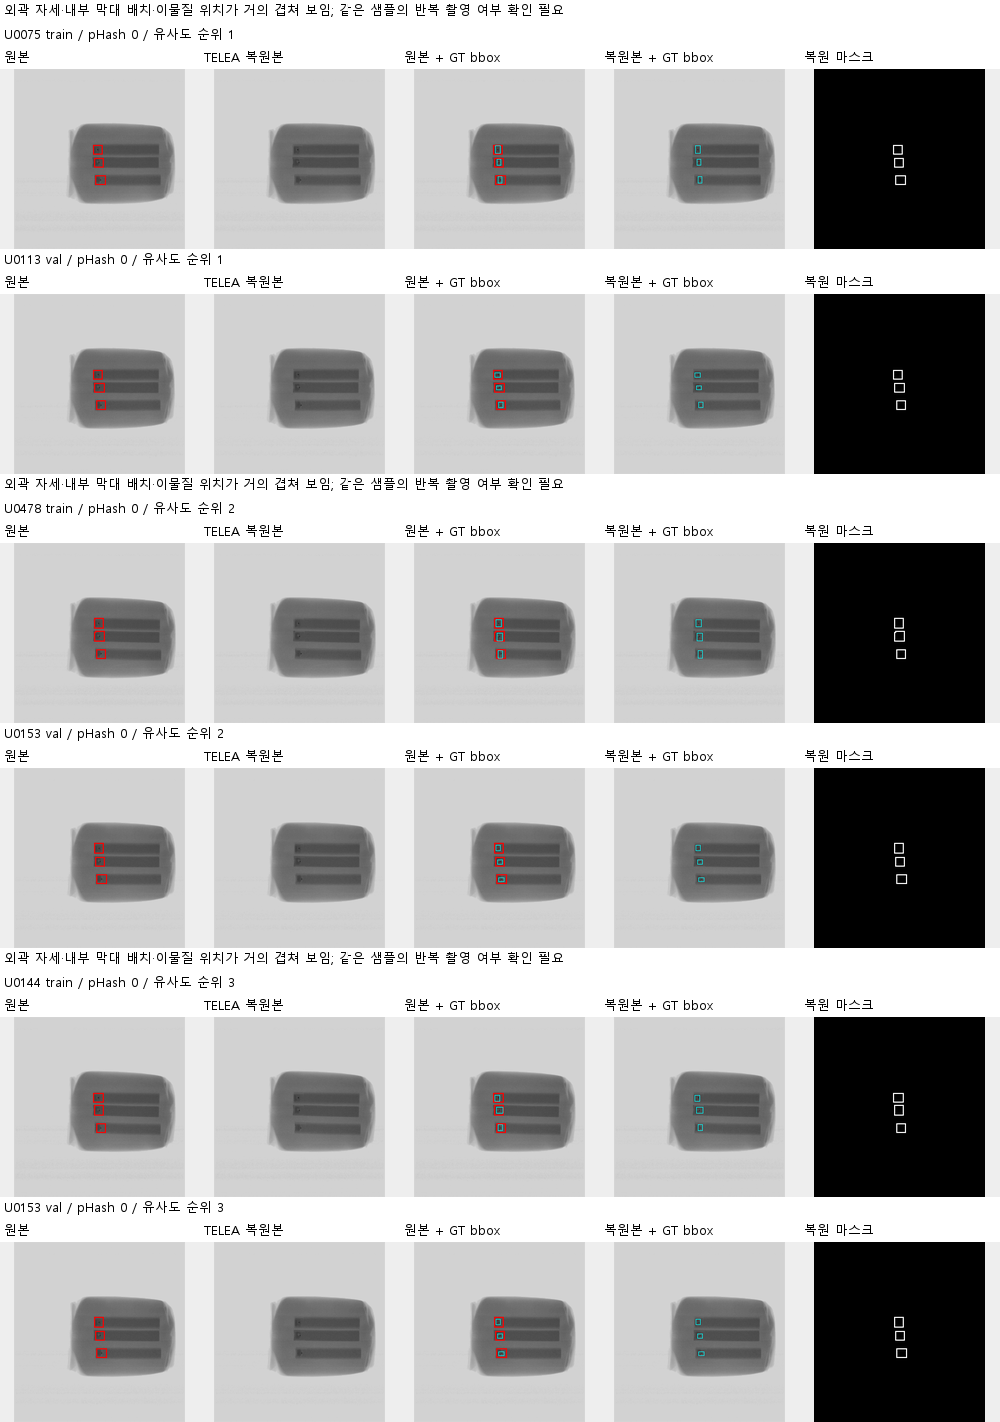

출처: outputs/yolo_512_telea_qa/위험_cross_split/위험_유사쌍_01.png


In [5]:
object_features = load_csv('outputs/foreign_object_condition_analysis/features.csv')
object_features = object_features[object_features['unique_id'].isin(selected_ids_512)].copy()
assert len(object_features) == 1163
assert set(object_features['unique_id']) == selected_ids_512
feature_counts = object_features.groupby('unique_id').size().sort_index()
manifest_counts = manifest.set_index('unique_id')['bbox_count'].sort_index()
assert feature_counts.equals(manifest_counts)
feature_split_check = object_features[['unique_id', 'split']].merge(
    manifest[['unique_id', 'split']], on='unique_id',
    suffixes=('_feature', '_manifest'), validate='many_to_one')
assert feature_split_check['split_feature'].equals(feature_split_check['split_manifest'])
print('512장에 연결된 bbox 1,163개의 크기·종횡비 분포')
display(object_features[['bbox_area','bbox_aspect_ratio','image_width','image_height']].describe())
display(object_features.groupby('split')['bbox_area'].agg(['count','min','median','max']).reindex(split_order))
show_png('outputs/yolo_512_telea_qa/위험_cross_split/위험_유사쌍_01.png',
         '512장 내 split 간 유사쌍 검토 예시: 동일 제품 확정 판정이 아님')

## 3. 512장 사각형 표시 제거 전처리

**목적:** 최종 512장의 컬러 주석 표시를 처리하고 라벨·복원 영역·변경 범위를 확인한다.  
**공식 평가항목 연결:** 1. 데이터 이해 및 진단, 5. 창의성·차별성.  

컬러 사각형은 후처리 주석이므로 실제 생산 영상에 같은 표시가 없을 때 모델이 주석에 의존할 위험이 있다.  
최종 512장에는 TELEA, radius 3, dilation 0을 적용했다.  
512장의 라벨 bbox 1,163개 중 141개가 복원 mask와 겹치며 해당 이미지 수는 91장이다.  
mask 밖 변경 픽셀 수는 0이다.  
이 검사는 변경 범위와 라벨 연결의 확인이며 실제 결함 신호의 완전 보존을 뜻하지 않는다.  

**전처리 선택의 보조 근거 — 기존 20장 PoC:** TELEA/NS, dilation 0/1/2, radius 1/2/3의 18개 조합을 비교했다.  
composite score는 GT 주변 변화·core 침범·잔존 표시·경계 변화를 종합한 보존성 지표이며 낮을수록 좋다.  
TELEA 최선은 약 5.672499, NS 최선은 약 5.774496이다.  
이 비교는 512장 전체의 방법별 재실험이 아니다.  
주석이 없는 정답 원본 없이 가려진 X-ray 신호 복원을 증명할 수는 없다.  

아래에는 512장 적용 결과를 먼저 제시하고, 선택 근거인 20장 보조 비교를 구분해 표시한다.


본 분석: 최종 512장 전처리 적용 결과


,images,bbox,method,radius,dilation,GT_overlap_images,GT_overlap_bbox,outside_mask_changed_pixels
0,512,1163,TELEA,3,0,91,141,0


보조 실험: 기존 20장 PoC의 전처리 방법 비교 (512장 성능 평가와 별도)


,method,best_composite_score,avg_composite_score,avg_contrast_change,avg_edge_excess
0,NS,5.774496,9.974400,0.232222,2.103364
1,TELEA,5.672499,9.967303,0.224444,2.208297


,method,dilation_px,radius,images,composite_score,mean_abs_gt_contrast_change,mean_mask_fraction_of_gt_core,residual_palette_pixels
0,TELEA,0,3,20,5.672499,0.050000,0.000000,0
1,TELEA,0,2,20,5.682334,0.050000,0.000000,0
2,NS,0,3,20,5.774496,0.050000,0.000000,0
3,NS,0,2,20,5.831811,0.050000,0.000000,0
4,TELEA,0,1,20,5.840780,0.050000,0.000000,0
5,NS,0,1,20,5.953837,0.050000,0.000000,0


20장 보조 실험의 비교 예시: ORIGINAL / MASK / TELEA / NS / GT


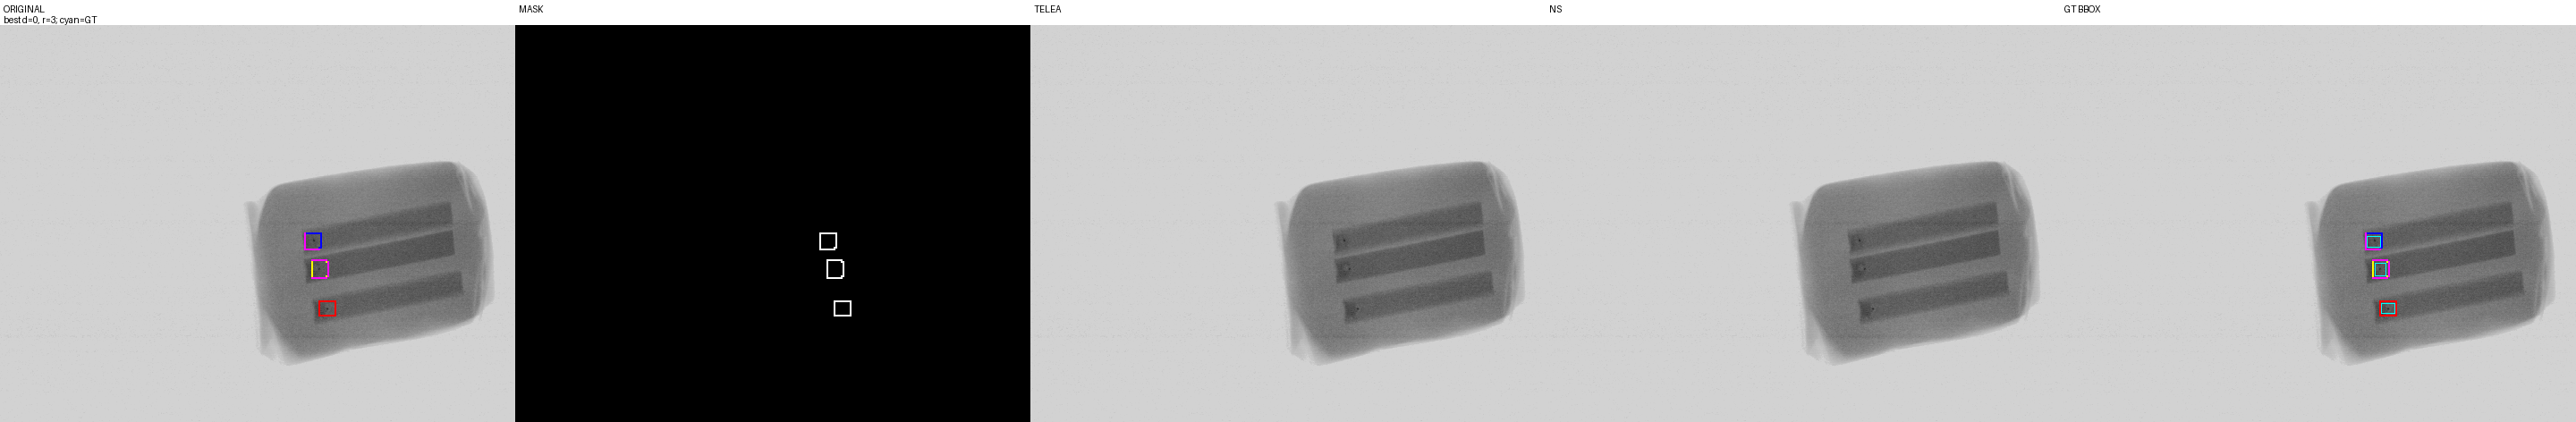

출처: outputs/inpainting_poc_20/figures/01_4184354a2a3c_comparison.png
20장 보조 실험의 비교 예시: ORIGINAL / MASK / TELEA / NS / GT


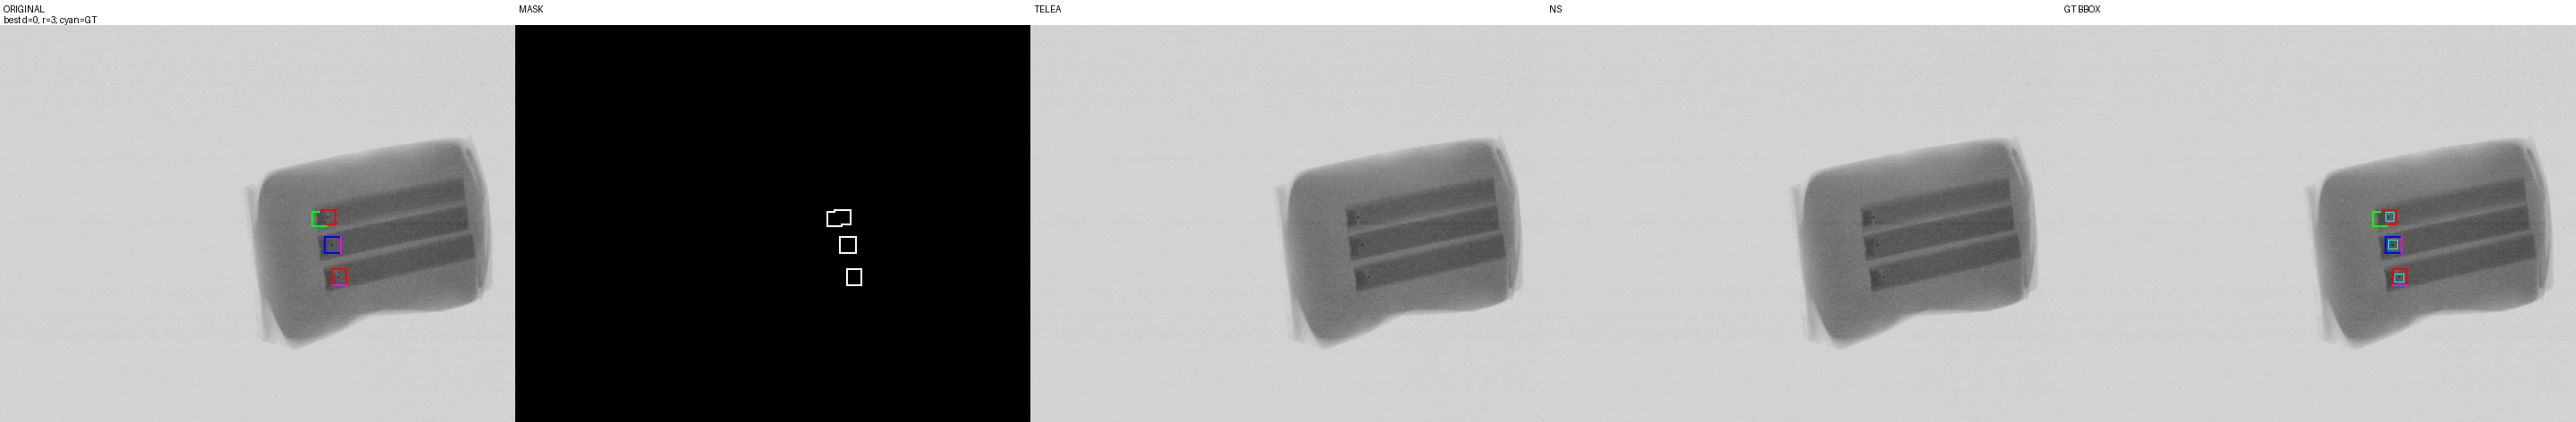

출처: outputs/inpainting_poc_20/figures/02_5f98bf110107_comparison.png


In [6]:
print('본 분석: 최종 512장 전처리 적용 결과')
assert int(manifest['overlap_bbox_count'].sum()) == restoration_summary['gt_mask_overlap_bbox']
assert int((manifest['gt_mask_overlap_pixels'] > 0).sum()) == restoration_summary['gt_mask_overlap_images']
assert int(manifest['outside_mask_changed_pixels'].sum()) == 0
display(pd.DataFrame([{'images':restoration_summary['images'], 'bbox':restoration_summary['bbox'],
    'method':restoration_summary['method'], 'radius':restoration_summary['radius'],
    'dilation':restoration_summary['dilation'], 'GT_overlap_images':restoration_summary['gt_mask_overlap_images'],
    'GT_overlap_bbox':restoration_summary['gt_mask_overlap_bbox'],
    'outside_mask_changed_pixels':restoration_summary['outside_mask_changed_pixels']}]))
print('보조 실험: 기존 20장 PoC의 전처리 방법 비교 (512장 성능 평가와 별도)')
method_table = load_csv('outputs/inpainting_poc_20/method_summary.csv')
method_comparison = method_table.groupby('method').agg(
    best_composite_score=('composite_score','min'), avg_composite_score=('composite_score','mean'),
    avg_contrast_change=('mean_abs_gt_contrast_change','mean'),
    avg_edge_excess=('mean_artificial_edge_excess','mean')).reset_index()
display(method_comparison)
display(method_table.sort_values('rank')[['method','dilation_px','radius','images','composite_score',
        'mean_abs_gt_contrast_change','mean_mask_fraction_of_gt_core','residual_palette_pixels']].head(6))
for path in sorted((ROOT/'outputs/inpainting_poc_20/figures').glob('*_comparison.png'))[:2]:
    show_png(path.relative_to(ROOT).as_posix(), '20장 보조 실험의 비교 예시: ORIGINAL / MASK / TELEA / NS / GT')

## 4. 512장 학습 입력의 shortcut 위험과 보조 진단

**목적:** 주석·복원 흔적이 탐지 단서가 될 위험을 설명하고 기존 보조 실험이 확인한 범위를 구분한다.  
**공식 평가항목 연결:** 5. 창의성·차별성.  

최종 512장 분석에서는 주석 제거의 변경 범위와 라벨 연결을 3절에서 확인했다.  
복원 흔적에 대한 모델 의존성은 이 확인만으로 판단할 수 없다.  

**기존 20장 PoC의 별도 진단:** baseline과 fake augmentation 모델에 대해 이물질이 없는 영역에 fake restoration을 추가한 paired 비교를 수행했다.  
34개 pair 중 holdout은 10개 pair(원본 이미지 6장), test는 5개 pair다.  
FR-FPR의 분모는 fake 영역 수다.  
여기서 test는 20장 PoC의 분할이며 본 분석의 Test 76장과 다르다.  

이 진단은 512장 최종 모델로 수행한 실험이 아니다.  
아래 표는 보조 진단 결과만 제시하며 512장 모델의 Precision/Recall/mAP와 합쳐 비교하지 않는다.  
최종 모델의 shortcut 위험을 직접 검증하려면 별도 진단이 필요하다.


보조 진단: 기존 20장 PoC 모델; 본 분석의 Test 76장 결과가 아님


,model,scope,diagnostic_pairs,source_images,fake_regions,fr_fpr,fake_fp_total,mean_fake_region_max_conf,mean_delta_confidence,new_fake_fp_count,gt_detection_loss_count,gt_detection_gain_count
0,baseline,all,34,20,34,0.000000,0,0.010927,0.000006,0,0,0
1,fake_aug,all,34,20,34,0.000000,0,0.011197,-0.000002,0,0,0
2,baseline,holdout,10,6,10,0.000000,0,0.008791,0.000005,0,0,0
3,fake_aug,holdout,10,6,10,0.000000,0,0.011428,-0.000079,0,0,0
6,baseline,test,5,3,5,0.000000,0,0.009017,-0.000001,0,0,0
7,fake_aug,test,5,3,5,0.000000,0,0.012157,-0.000152,0,0,0


,scope,metric,test,n,paired_mean_difference,p_value
0,all,fake_max_confidence,Wilcoxon signed-rank,34,0.000270,0.342850
1,all,delta_confidence,Wilcoxon signed-rank,34,-0.000008,0.262857
2,all,fake_fp_present,McNemar exact,34,0.000000,1.000000
3,holdout,fake_max_confidence,Wilcoxon signed-rank,10,0.002637,0.105469
4,holdout,delta_confidence,Wilcoxon signed-rank,10,-0.000085,0.193359
5,holdout,fake_fp_present,McNemar exact,10,0.000000,1.000000


최대 confidence 변화 사례의 기존 overlay: fake FP 확정 사례가 아님


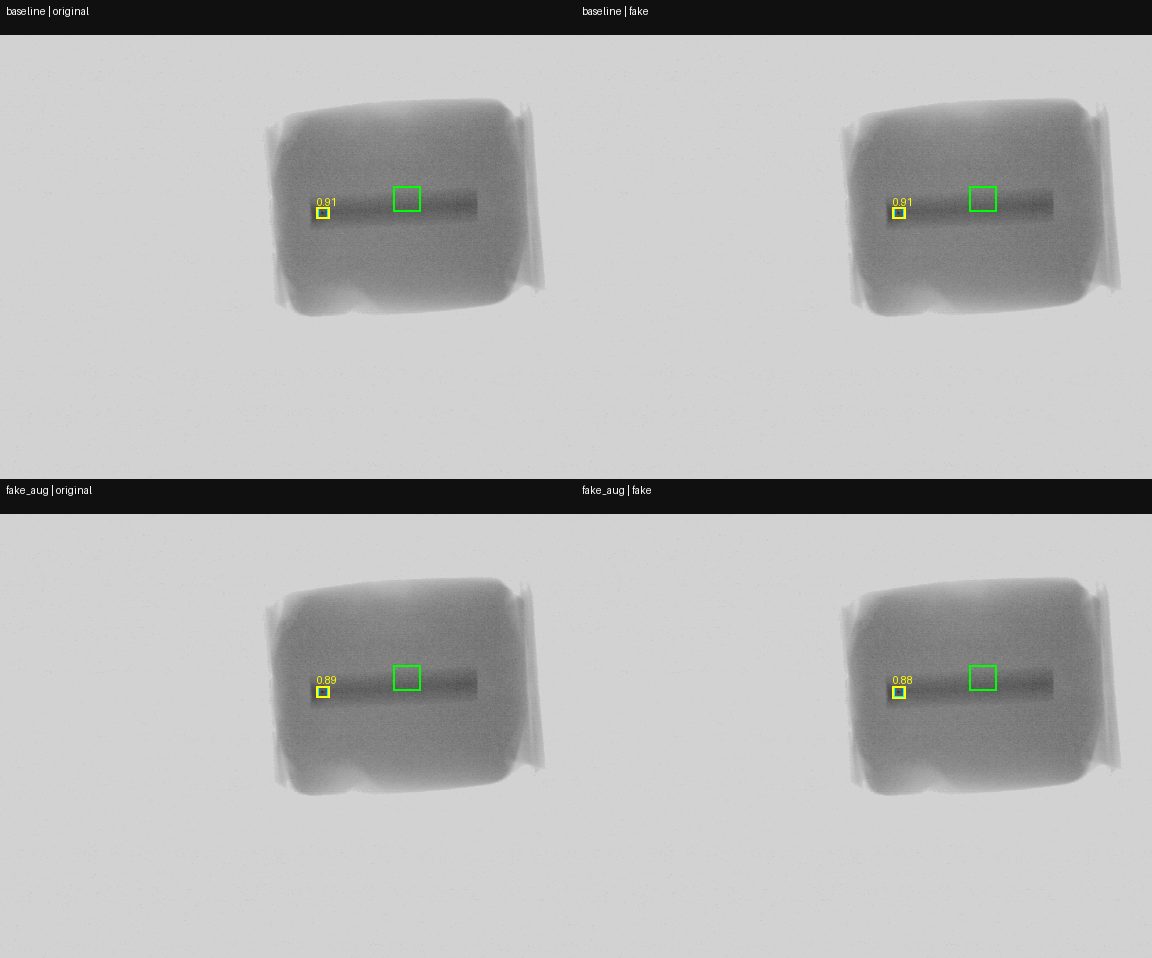

출처: outputs/shortcut_diagnostic_gpu/cases/E_largest_delta_pair_0002/overlay.png


In [7]:
print('보조 진단: 기존 20장 PoC 모델; 본 분석의 Test 76장 결과가 아님')
shortcut = load_csv('outputs/shortcut_diagnostic_gpu/model_summary.csv')
shortcut_cols = ['model','scope','diagnostic_pairs','source_images','fake_regions','fr_fpr',
                 'fake_fp_total','mean_fake_region_max_conf','mean_delta_confidence',
                 'new_fake_fp_count','gt_detection_loss_count','gt_detection_gain_count']
display(shortcut[shortcut['scope'].isin(['all','holdout','test'])][shortcut_cols])
display(load_csv('outputs/shortcut_diagnostic_gpu/paired_comparison.csv')[['scope','metric','test','n',
        'paired_mean_difference','p_value']])
show_png('outputs/shortcut_diagnostic_gpu/cases/E_largest_delta_pair_0002/overlay.png',
         '최대 confidence 변화 사례의 기존 overlay: fake FP 확정 사례가 아님')

**보조 진단의 결과:** 기존 20장 PoC의 baseline과 fake augmentation 모델은 all/holdout/test 범위에서 FR-FPR=0, 새 fake FP=0, GT loss/gain=0이었다.  
해당 표본과 fake 생성 방식에서는 복원 흔적에 의존한다는 강한 증거가 관찰되지 않았다.  

이 결과는 최종 512장 모델의 shortcut 부재나 일반화 성능을 입증하지 않는다.  
512장 본 실험의 성능은 다음 절의 동일 분할 모델 비교와 Test 평가로 확인한다.


## 5. 동일한 512장 분할의 모델 비교와 최종 모델

**목적:** Train 359장 / Val 77장 / Test 76장에서 완료된 YOLO11n·YOLOv8n 실험을 비교한다.  
**공식 평가항목 연결:** 2. AI 예측모델 개발.  

총 11개 완료 실험은 YOLO11n 설정 실험 9개와 YOLOv8n 비교 실험 2개다.  
실험 수와 모델 구조 수를 구분하며, 구조는 YOLO11n·YOLOv8n의 2종이다.  
취소된 실행과 다른 데이터 규모의 PoC는 포함하지 않는다.  

먼저 전체 설정을 보여주고, **동일 조건의 구조 비교**와 **YOLO11n 증강 비교**를 따로 제시한다.  
구조 비교는 두 모델 모두 imgsz640 / batch4 / AdamW / lr0.001 / 최대 200 epoch / patience50 / seed42다.  
기본 증강은 translate0.005 / scale0.2 / mosaic0.2이고 회전·뒤집기·HSV·mixup은 0이다.  
추가 감마는 0.9–1.1, 확률 20%이며 노이즈는 표준편차 1–3(0–255 밝기 기준), 확률 10%다.  
각 구조 비교 쌍의 저장 설정이 모델명과 실행 메타데이터 외에 같은지 코드로 확인한다.  
각 실험의 저장 이미지 수와 데이터 경로는 확인하지만, 과거 실행별 데이터 해시가 없어 당시 입력의 완전 동일성을 소급 증명하지는 않는다.  

Val과 Test를 분리해 보고하며, 새 비교 결과만으로 기존 후속 분석 모델을 교체하지 않는다.  
`F1_from_reported_PR`은 저장 Precision·Recall의 조화평균으로, 6절의 고정 threshold·IoU 매칭 F1과 다르다.

In [8]:
experiment_index = load_csv('outputs/yolo_runs/experiments.csv')
indexed = experiment_index.set_index('run_name').to_dict('index')
run_root = ROOT/'outputs/yolo_runs'
comparison_manifest = load_json('outputs/model_comparison/comparison_manifest.json')
assert file_sha(source('outputs/yolo_512_telea/manifest.csv')) == comparison_manifest['dataset_manifest_sha256']
run_dirs = [run_root/name for name in comparison_manifest['runs']]
assert len(run_dirs) == len(set(comparison_manifest['runs'])) == 11
run_rows=[]
for run_dir in run_dirs:
    relative=run_dir.relative_to(ROOT).as_posix()
    saved=json.loads((run_dir/'summary.json').read_text(encoding='utf-8-sig')) if (run_dir/'summary.json').exists() else {}
    if tuple(saved.get(key) for key in ('train_images','val_images','test_images')) != (359,77,76):
        continue
    saved=load_json(relative+'/summary.json')
    config=load_json(relative+'/experiment_config.json') if (run_dir/'experiment_config.json').exists() else {}
    fallback=indexed.get(run_dir.name,{})
    row={'run_name':run_dir.name,'model':config.get('model',fallback.get('model')),
         'batch':config.get('batch',fallback.get('batch')),'imgsz':config.get('imgsz',fallback.get('imgsz')),'lr0':config.get('lr0',fallback.get('lr0')),
         'augmentation':fallback.get('augmentation','미저장'),'best_epoch':saved.get('best_epoch',fallback.get('best_epoch')),
         'train_images':saved.get('train_images'),'val_images':saved.get('val_images'),'test_images':saved.get('test_images'),
         'weights_present':(run_dir/'weights/best.pt').exists(),
         'metrics_source':relative+'/summary.json' if saved else ('outputs/yolo_runs/experiments.csv' if fallback else '미저장')}
    for split in ('val','test'):
        for metric in ('precision','recall','map50','map50_95'):
            row[f'{split}_{metric}']=saved.get(f'{split}_{metric}',fallback.get(f'{split}_{metric}',np.nan))
        p,r=row[f'{split}_precision'],row[f'{split}_recall']
        row[f'{split}_F1_from_reported_PR']=harmonized_f1(p,r) if pd.notna(p) and pd.notna(r) else np.nan
    row['comparison_group']='512장 본 실험 (359/77/76)'
    if (run_dir/'results.csv').exists():
        logs=load_csv(relative+'/results.csv')
        row['logged_epochs']=len(logs)
    else:
        row['logged_epochs']=0
    row['metrics_status']='평가 저장됨' if pd.notna(row['test_map50']) else '평가 지표 없음'
    run_rows.append(row)
models=pd.DataFrame(run_rows)
assert not models.empty
assert (models[['train_images','val_images','test_images']].to_numpy() == np.array([359,77,76])).all()
print('주 성능표: 동일한 512장 분할의 학습 설정 비교')
final_run=PureWindowsPath(error_summary['provenance']['model']).parents[1].name
models['selected_final']=models['run_name']==final_run
models['experiment_id'] = [f'R{i:02d}' for i in range(1, len(models) + 1)]
assert models['selected_final'].sum() == 1
print('실험 설정 (R번호는 아래 성능표와 동일)')
settings = models[['experiment_id','model','imgsz','lr0','augmentation','best_epoch','selected_final']].copy()
settings.columns = ['실험','모델','입력 크기','학습률','증강','best epoch','최종 모델']
display(settings)
for split, title in [('val', 'Val 77장 성능'), ('test', 'Test 76장 성능')]:
    print(title + ' (저장 validator 지표, 0–1 척도)')
    metrics = models[['experiment_id', f'{split}_precision', f'{split}_recall',
                     f'{split}_F1_from_reported_PR', f'{split}_map50', f'{split}_map50_95']].copy()
    metrics.columns = ['실험','Precision','Recall','F1(P/R)','mAP50','mAP50–95']
    assert np.isfinite(metrics.iloc[:, 1:].to_numpy(dtype=float)).all()
    assert metrics.iloc[:, 1:].ge(0).all().all() and metrics.iloc[:, 1:].le(1).all().all()
    display(metrics)
print('실험 번호와 저장 폴더 연결')
display(models[['experiment_id','run_name']].rename(columns={'experiment_id':'실험','run_name':'저장 폴더'}))
final_model = models[models.selected_final].iloc[0]
assert final_model['weights_present']
final_weight=f'outputs/yolo_runs/{final_run}/weights/best.pt'
assert file_sha(source(final_weight))==error_summary['provenance']['model_sha256']
print('기존 후속 분석에서 고정된 최종 모델:',final_weight)

# Saved CONFIG comparisons: missing gamma/noise probabilities in older runs mean disabled.
pair_setting_keys = ['preprocessing','data','epochs','imgsz','batch','device','workers','optimizer',
    'lr0','lrf','momentum','weight_decay','warmup_epochs','patience','seed','deterministic','pretrained',
    'degrees','translate','scale','shear','perspective','flipud','fliplr','mosaic','mixup',
    'hsv_h','hsv_s','hsv_v','gamma_p','noise_p','plots','save','conf']
paired_comparison_rows = []
for pair in comparison_manifest['matched_architecture_pairs']:
    configs = [load_json(f"outputs/yolo_runs/{pair[key]}/experiment_config.json") for key in ('v8','v11')]
    for key in pair_setting_keys:
        default = 0.0 if key in ('gamma_p','noise_p') else None
        assert configs[0].get(key, default) == configs[1].get(key, default), (pair['label'], key)
    assert [config['model'] for config in configs] == ['yolov8n.pt','yolo11n.pt']
    for probability, bounds in [('gamma_p', ('gamma_min','gamma_max')),
                                ('noise_p', ('noise_std_min','noise_std_max'))]:
        if configs[0].get(probability, 0) > 0:
            assert all(configs[0][key] == configs[1][key] for key in bounds)
    print('동일 조건 구조 비교:', pair['label'], '(640 / batch4 / seed42)')
    paired = models.set_index('run_name').loc[[pair['v8'], pair['v11']]].copy()
    for split, title in [('val','Validation 77장'), ('test','Test 76장')]:
        metrics = paired[['model',f'{split}_precision',f'{split}_recall',f'{split}_map50',f'{split}_map50_95']].copy()
        metrics.columns = ['모델','Precision','Recall','mAP50','mAP50–95']
        print(title)
        display(metrics.reset_index(drop=True))
        delta = metrics.iloc[1,1:].astype(float) - metrics.iloc[0,1:].astype(float)
        paired_comparison_rows.append({'조건':pair['label'],'분할':title,
            **{f'{key} 차이(pp)': float(value)*100 for key,value in delta.items()}})
print('구조 비교 차이: YOLO11n − YOLOv8n, 퍼센트포인트(pp)')
display(pd.DataFrame(paired_comparison_rows))
print('YOLO11n 증강 비교: 모델·640 해상도·batch4 고정')
study = models.set_index('run_name').loc[comparison_manifest['augmentation_study_runs']].copy()
study['조건'] = ['기본 증강','기본 증강 + 감마','기본 증강 + 감마 + 노이즈']
for split, title in [('val','Validation'), ('test','Test')]:
    table = study[['조건',f'{split}_precision',f'{split}_recall',f'{split}_map50',f'{split}_map50_95']].copy()
    table.columns = ['조건','Precision','Recall','mAP50','mAP50–95']
    print(title)
    display(table.reset_index(drop=True))
assert final_run == comparison_manifest['fixed_downstream_model']
assert len(models) == len(comparison_manifest['runs'])


주 성능표: 동일한 512장 분할의 학습 설정 비교


실험 설정 (R번호는 아래 성능표와 동일)


,실험,모델,입력 크기,학습률,증강,best epoch,최종 모델
0,R01,yolo11n.pt,1280,0.000500,noaug,6,False
1,R02,yolo11n.pt,1280,0.000500,noaug,6,False
2,R03,yolo11n.pt,1280,0.001000,aug_tr0.005_sc0.2_mos0.2,44,False
3,R04,yolo11n.pt,1280,0.001000,noaug,7,True
4,R05,yolo11n.pt,640,0.001000,aug_tr0.005_sc0.2_mos0.2_gam0.9-1.1p0.2_noise1-3p0.1,21,False
5,R06,yolo11n.pt,640,0.001000,aug_tr0.005_sc0.2_mos0.2_gam0.9-1.1p0.2,61,False
6,R07,yolo11n.pt,640,0.001000,aug_tr0.005_sc0.2_mos0.2,43,False
7,R08,yolo11n.pt,640,0.001000,noaug,8,False
8,R09,yolo11n.pt,960,0.001000,noaug,4,False
9,R10,yolov8n.pt,640,0.001000,aug_tr0.005_sc0.2_mos0.2_gam0.9-1.1p0.2,36,False


Val 77장 성능 (저장 validator 지표, 0–1 척도)


,실험,Precision,Recall,F1(P/R),mAP50,mAP50–95
0,R01,0.971414,0.970938,0.971176,0.977442,0.448577
1,R02,0.971414,0.970938,0.971176,0.977442,0.448577
2,R03,0.965583,0.961907,0.963741,0.954928,0.494868
3,R04,0.965989,0.973800,0.969879,0.970014,0.473756
4,R05,0.964053,0.965714,0.964883,0.964420,0.473706
5,R06,0.976580,0.977143,0.976861,0.968612,0.457394
6,R07,0.959072,0.960000,0.959536,0.932074,0.462831
7,R08,0.959987,0.959680,0.959833,0.948866,0.436085
8,R09,0.931386,0.925714,0.928541,0.946788,0.447237
9,R10,0.958713,0.960000,0.959356,0.950134,0.454533


...

,조건,분할,Precision 차이(pp),Recall 차이(pp),mAP50 차이(pp),mAP50–95 차이(pp)
0,기본 증강,Validation 77장,-1.759967,-1.714286,-3.933333,-0.170577
1,기본 증강,Test 76장,1.298874,1.250000,2.679489,2.501809
2,기본 증강 + 감마,Validation 77장,1.786648,1.714286,1.847778,0.286088
3,기본 증강 + 감마,Test 76장,0.687426,0.625000,2.250060,-0.048873


YOLO11n 증강 비교: 모델·640 해상도·batch4 고정
Validation


,조건,Precision,Recall,mAP50,mAP50–95
0,기본 증강,0.959072,0.960000,0.932074,0.462831
1,기본 증강 + 감마,0.976580,0.977143,0.968612,0.457394
2,기본 증강 + 감마 + 노이즈,0.964053,0.965714,0.964420,0.473706


Test


,조건,Precision,Recall,mAP50,mAP50–95
0,기본 증강,0.956072,0.956250,0.926064,0.384190
1,기본 증강 + 감마,0.955614,0.956250,0.932648,0.352791
2,기본 증강 + 감마 + 노이즈,0.931216,0.930757,0.884734,0.367971


**최종 모델 선정 근거와 범위:** 기존 후속 평가에서 고정한 모델은 TELEA512 / YOLO11n / imgsz1280 / batch4 / lr0.001 / no augmentation / seed42의 best.pt(best epoch7)이다.  
저장 Val Recall≈0.973800, mAP50≈0.970014, mAP50–95≈0.473756으로 640/960 no-aug baseline보다 높은 위치·검출 성능을 보였다.  
lr0.0005는 Val mAP50≈0.977442로 더 높지만 mAP50–95≈0.448577이며, augmentation 실행은 mAP50–95≈0.494868이 더 높지만 Recall≈0.961907이다.  
**관찰됨:** 최종 모델 Val F1_from_reported_PR=**0.969879**이고 lr0.0005 모델은 **0.971176**으로, **F1 최대 모델은 별도로 존재했다**(본 실험 비교 기준).  
최종 모델이 F1 최적이라고 주장하지 않는다.  
**사후 판단:** 최종 모델 유지는 Recall, bbox 안정성 검토의 지표인 Val mAP50–95, 기존 고정 baseline과 후속 분석의 일관성을 함께 고려한 설명이다.  
lr0.0005보다 Recall과 mAP50–95는 높지만 F1과 mAP50은 낮다는 교환관계를 숨기지 않는다.  
mAP50–95는 반복 촬영 간 bbox 안정성을 직접 측정한 지표가 아니므로 bbox 안정성 우위를 독립적으로 검증했다고 표현하지 않는다.  
기록에 없는 사전 선정 기준을 추가하지 않았으며, 현재 설명은 기존 결과에 대한 종합적인 사후 판단이다.  
현재 노트북은 기존 고정 baseline과 후속 검증의 연결을 유지하며 Test 결과로 모델을 재선택하지 않는다.  
lr0.0005의 run02는 반복 실행이므로 별도 신규 모델 구조로 세지 않는다.  
**5.1. YOLOv8n·YOLO11n 구조 비교 — 관찰됨**  
기본 증강·640 조건에서 Val은 YOLOv8n이 네 지표 모두 높았다.  
Test는 YOLO11n이 네 지표 모두 높았으며, mAP50은 0.926064 대 0.899269, mAP50–95는 0.384190 대 0.359172였다.  
따라서 이 조건의 Test에서는 YOLO11n이 우세하지만, 모델 구조가 모든 조건에서 최고라고 단정하지 않는다.  
감마만 추가한 동일 조건에서는 YOLO11n이 Val의 네 지표 모두 높았다.  
Test에서는 YOLO11n의 Precision·Recall·mAP50이 높고, mAP50–95는 YOLOv8n 0.353280이 YOLO11n 0.352791보다 근소하게 높았다.  
각 조건은 seed42의 단일 실행이며 반복 seed 검증이나 통계적 유의성 검증은 수행하지 않았다.  
1280 최종 모델과 640 YOLOv8n의 차이를 모델 구조만의 효과로 해석하지 않는다.  

**5.2. 감마·노이즈 추가 비교 — 관찰됨**  
YOLO11n의 기본 증강 대비 감마+노이즈는 Val의 네 지표가 상승했지만 Test의 네 지표는 하락했다.  
감마만 사용하면 기본 증강 대비 Val Precision·Recall·mAP50은 상승하고 mAP50–95는 하락했다.  
Test Recall은 같고 mAP50은 상승했지만 Precision과 mAP50–95는 하락했다.  
YOLOv8n의 감마 추가는 Val의 네 지표를 모두 낮췄으며 Test에서는 Precision·Recall·mAP50이 상승하고 mAP50–95가 하락했다.  
추가 증강의 일관된 개선은 확인되지 않았고, 노이즈가 하락의 원인이라고 단정하지 않는다.  

**최종 제출 모델 유지**  
기존 1280 YOLO11n / no augmentation 모델의 Test mAP50–95는 0.407136이다.  
이는 이번 640 구조 비교 후보보다 높지만, 최종 모델 유지 근거는 기존 고정 모델과 임계값·오류 분석의 연결이며 사후 Test 최고값 선택으로 표현하지 않는다.  
새 비교의 best.pt에는 기존 FN12·FP8 및 threshold 정책을 그대로 적용했다고 주장하지 않는다.


기존 학습 로그: 첫3 epoch / 마지막3 epoch


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,48.205900,2.638290,3.529900,1.822300,0.946670,0.405710,0.397220,0.163990,2.132330,4.142340,1.412730,0.000330,0.000330,0.067367
1,2,59.775200,2.134240,1.120710,1.463820,0.896670,0.908570,0.946540,0.407140,1.996060,1.223290,1.388500,0.000660,0.000660,0.034363
2,3,71.131700,2.050160,0.985830,1.421210,0.948110,0.939640,0.948930,0.441700,1.939620,0.960500,1.349980,0.000986,0.000986,0.001357
54,55,650.299000,0.403740,0.289050,0.786200,0.982480,0.977140,0.968910,0.415130,2.017890,0.703300,1.669730,0.000733,0.000733,0.000733
55,56,660.755000,0.391880,0.283020,0.784230,0.959590,0.960000,0.951570,0.413170,2.002790,0.708900,1.672680,0.000728,0.000728,0.000728
56,57,671.559000,0.375670,0.274880,0.782070,0.976290,0.971430,0.964720,0.404460,2.034270,0.697320,1.678760,0.000723,0.000723,0.000723


기존 최종 모델 validation PR curve


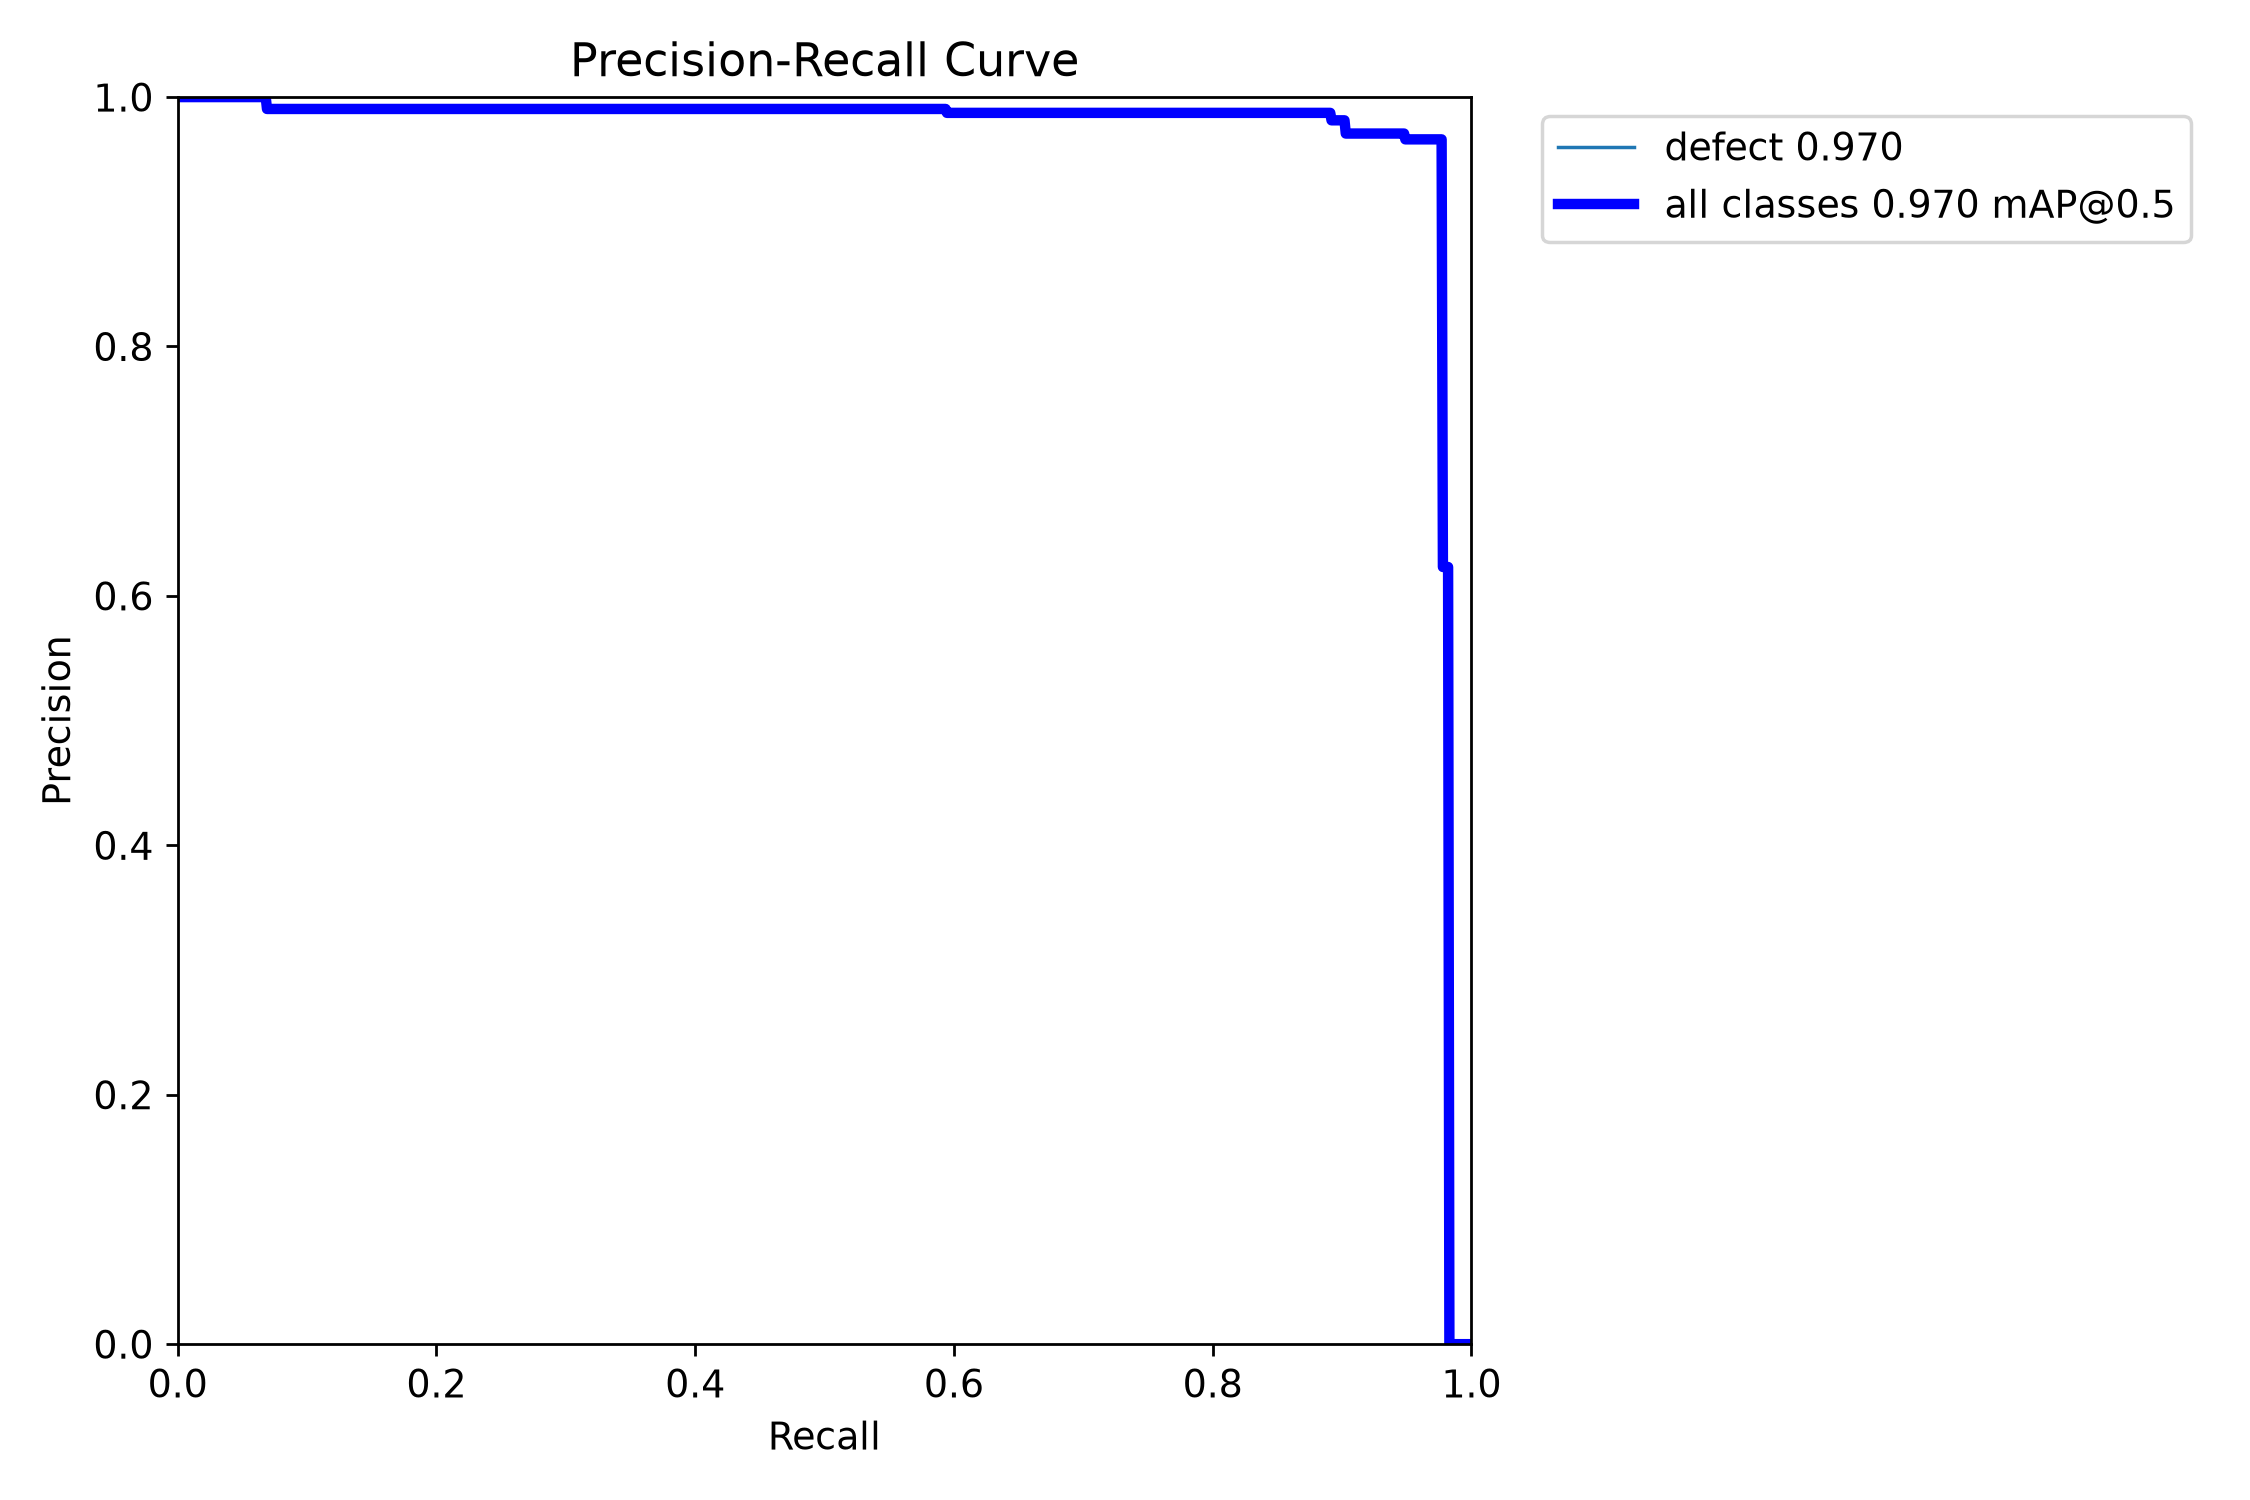

출처: outputs/yolo_runs/telea_512_yolo11n_e200_img1280_b4_adamw_lr0.001_wd0.0005_noaug_s42/validation/BoxPR_curve.png


In [9]:
final_logs=load_csv(f'outputs/yolo_runs/{final_run}/results.csv')
final_logs.columns=final_logs.columns.str.strip()
print('기존 학습 로그: 첫3 epoch / 마지막3 epoch')
display(pd.concat([final_logs.head(3),final_logs.tail(3)]).drop_duplicates())
validation_curve=f'outputs/yolo_runs/{final_run}/validation/BoxPR_curve.png'
if (ROOT/validation_curve).exists():
    show_png(validation_curve,'기존 최종 모델 validation PR curve')
else:
    print('해당 PR PNG는 저장되어 있지 않음; 기존 성능표와 로그를 사용')


## 6. 512장 분할 중 Val 77장·Test 76장의 Threshold 분석

**목적:** Val에서 선택한 threshold 정책의 Precision/Recall/F1과 FN/FP 비용을 검토하고 잠긴 정책을 Test 결과에 연결한다.  
**공식 평가항목 연결:** 2. AI 예측모델 개발, 4. 현장 활용방안.  

정책 선택은 Val 77장·GT 175개에서 수행하고 고정한 정책을 Test 76장·GT 160개에 적용한다.  
Train이나 512장 전체를 평가 분모로 사용하지 않는다.  

최종 정책은 **T_low=0.20, T_high=0.25**로 유지한다.  
**0.20은 F1 optimum이 아니라 screening lower bound**이며 자동 NG 후보 상한은 0.25다.  
confidence는 보정된 불량 확률이 아니다.  
Val에서 T_low 후보 0.05/0.10/0.15/0.20/0.25와 추가 FP 예산 7개(0.10/image), 재검 이미지 예산 20% 안에서 FN 복구 최대·FP 최소·동률이면 높은 threshold를 선택했다.  
Best-F1 단일 threshold0.31은 비교용이고,0.20은 재현율 중심 정책으로 잠겼다.  
Test로 threshold를 재선택하지 않았다.


정책 선택: Val 77장 / GT 175개


,threshold,TP,FN,FP,precision,recall,F1,FP_per_image
3,0.020000,172,3,117,0.595156,0.982857,0.741379,1.519481
6,0.050000,171,4,43,0.799065,0.977143,0.879177,0.558442
11,0.100000,171,4,19,0.900000,0.977143,0.936986,0.246753
16,0.150000,171,4,15,0.919355,0.977143,0.947368,0.194805
21,0.200000,171,4,12,0.934426,0.977143,0.955307,0.155844
26,0.250000,170,5,11,0.939227,0.971429,0.955056,0.142857
32,0.310000,170,5,9,0.949721,0.971429,0.960452,0.116883


Val 정책별 탐지 성능


,policy,T_low,T_high,TP,FN,FP,precision,recall,F1
0,Baseline,0.250000,0.250000,170,5,11,0.939227,0.971429,0.955056
1,Best_F1,0.310000,0.310000,170,5,9,0.949721,0.971429,0.960452
2,Recall_oriented,0.200000,0.200000,171,4,12,0.934426,0.977143,0.955307
3,Two_threshold,0.200000,0.250000,171,4,12,0.934426,0.977143,0.955307
4,High_sensitivity,0.020000,0.020000,172,3,117,0.595156,0.982857,0.741379


Val 정책별 추가 FP와 검토 부담


,policy,FN_Recovery,Added_FP,band_images,reinspection_images
0,Baseline,0,0,0,0
1,Best_F1,0,-2,0,0
2,Recall_oriented,1,1,0,0
3,Two_threshold,1,1,2,0
4,High_sensitivity,2,106,0,0


,selection_split,T_low,T_high,added_FP_budget,review_image_budget
0,val,0.200000,0.250000,7,0.200000


기존 Val threshold 곡선


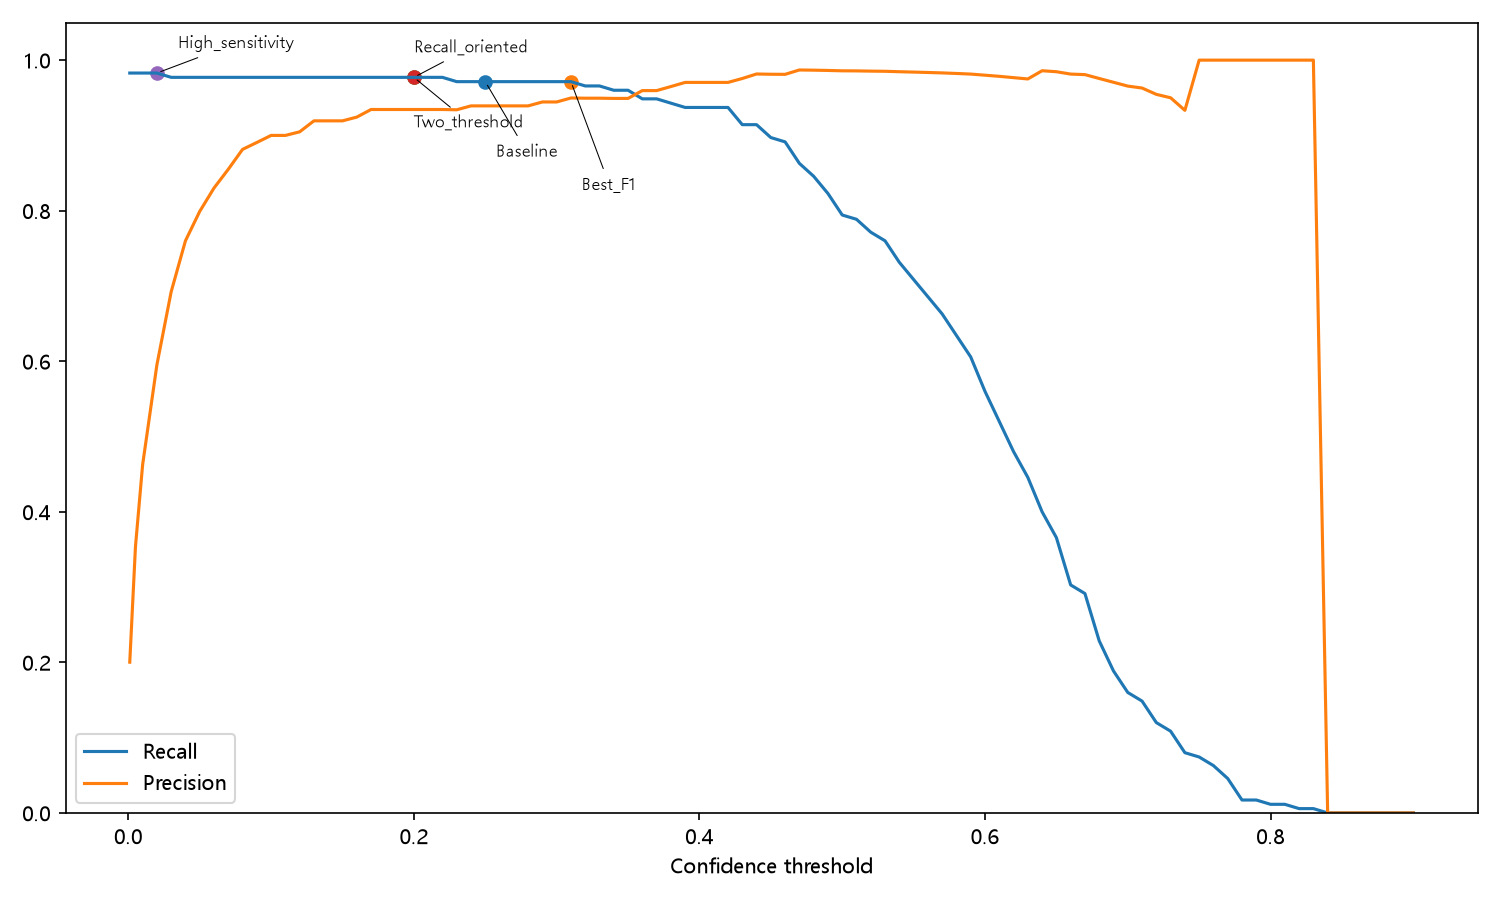

출처: outputs/safety_threshold_policy/visualizations/val_threshold_curve.png
고정 정책 평가: Test 76장 / GT 160개


,policy,threshold,TP,FN,FP,precision,recall,F1
0,Baseline,0.250000,148,12,8,0.948718,0.925000,0.936709
1,Final_policy,0.200000,148,12,8,0.948718,0.925000,0.936709


Test 이미지 분류와 검토 부담


,policy,band_detections,reinspection_images,normal_candidate_images
0,Baseline,0,0,4
1,Final_policy,0,0,4


In [10]:
val_sweep=load_csv('outputs/safety_threshold_policy/val_threshold_sweep.csv')
val_policies=load_csv('outputs/safety_threshold_policy/val_policy_candidates.csv')
test_policies=load_csv('outputs/safety_threshold_policy/test_policy_result.csv')
assert (val_sweep['TP'] + val_sweep['FN']).eq(175).all()
assert (val_policies['TP'] + val_policies['FN']).eq(175).all()
assert (test_policies['TP'] + test_policies['FN']).eq(160).all()
# 저장 TP/FN/FP로 지표 재계산. 예측 0개일 때 Precision=0인 저장 규칙을 적용한다.
for table in (val_sweep, val_policies, test_policies):
    precision_check = (table['TP'] / (table['TP'] + table['FP']).replace(0, np.nan)).fillna(0.0)
    recall_check = table['TP'] / (table['TP'] + table['FN'])
    f1_check = 2 * table['TP'] / (2 * table['TP'] + table['FP'] + table['FN'])
    for metric, calculated in [('precision', precision_check), ('recall', recall_check), ('F1', f1_check)]:
        assert np.allclose(table[metric], calculated, rtol=1e-9, atol=1e-12), metric
print('정책 선택: Val 77장 / GT 175개')
display(val_sweep[val_sweep['threshold'].isin([.02,.05,.10,.15,.20,.25,.31])]
        [['threshold','TP','FN','FP','precision','recall','F1','FP_per_image']])
print('Val 정책별 탐지 성능')
display(val_policies[['policy','T_low','T_high','TP','FN','FP','precision','recall','F1']])
print('Val 정책별 추가 FP와 검토 부담')
display(val_policies[['policy','FN_Recovery','Added_FP','band_images','reinspection_images']])
assert locked_policy['selection_split']=='val'
assert locked_policy['selected']['T_low']==.20 and locked_policy['selected']['T_high']==.25
display(pd.DataFrame([{'selection_split':locked_policy['selection_split'],
        'T_low':locked_policy['selected']['T_low'],'T_high':locked_policy['selected']['T_high'],
        'added_FP_budget':locked_policy['added_FP_budget'],'review_image_budget':locked_policy['review_image_budget']}]))
show_png('outputs/safety_threshold_policy/visualizations/val_threshold_curve.png',
         '기존 Val threshold 곡선')
print('고정 정책 평가: Test 76장 / GT 160개')
display(test_policies[['policy','threshold','TP','FN','FP','precision','recall','F1']])
print('Test 이미지 분류와 검토 부담')
display(test_policies[['policy','band_detections','reinspection_images','normal_candidate_images']])

**결과 해석:** Val에서 0.25→0.20은 TP 170→171, FN 5→4, FP 11→12로 FN 1개 복구/FP 1개 증가였다.  
그러나 Val middle band가 있는 2개 이미지는 이미 다른 high-confidence bbox로 자동 NG여서 추가 재검 이미지는 0장이었다.  
Test에는 0.20–0.25 band 자체가 없고 baseline/final 정책 모두 TP 148/FN 12/FP 8, Recall92.50%, Precision94.87%, F1≈93.67%였다.  
Test 재검 이미지도 0/76으로 운영 개선을 입증하지 못했다.  
‘정상 후보’4장도 GT가 있는 이미지이므로 정상 보증이 아니다.  
학습 summary의 Test P/R은 validator 집계이고, 이 표는 고정 threshold와 IoU 0.5 일대일 매칭 집계이므로 값이 조금 다른 것이 오류는 아니다.


## 7. 512장 분할 중 Test 76장의 FN/FP 오류분석

**목적:** 저장된 Test FN 12건·FP 8건의 bbox·confidence·IoU·크기·대비·위치·복원 조건을 비교하여 오류 집중 조건을 도출한다.  
**공식 평가항목 연결:** 3. 영향요인 및 오류분석, 5. 창의성·차별성.  

오류 분석 대상은 최종 512장 중 Test 76장의 GT 160개다.  
TP 148개와 FN 12개의 합이 GT 160개이며 FP는 8개다.  
조건별 FN/GT 비율은 Test 내부 비율이고 512장 전체의 미검출률을 뜻하지 않는다.  

수정된 `outputs/error_analysis`를 사용한다.  
FN candidate IoU는 표시 candidate와 해당 GT의 직접 IoU이며 threshold 미만 후보도 계산한다.  
평가 매칭 대상은 threshold 이상 후보로 유지하므로 `low_confidence_localization_success`라도 Test FN이다.  
주 분류는 기존 시각화 candidate 선택 기준이며, 다른 FN에 존재하는 저점수 IoU≥0.5 후보는 별도 열에 보존한다.  
localization_failure는 관찰된 위치/크기 실패 기전이며 정상 구조 오인이나 복원 흔적의 물리적 원인을 확정한 라벨이 아니다.  

**선택 candidate 기준 주 분류:** localization_failure8/12, low_confidence_localization_success3/12, low_confidence_localization_failure1/12를 유지한다.  
**선택 candidate 기준 주 분류에서는 66.7%가 localization failure**이며, FN 원인의 66.7%가 유일하게 위치 실패라고 단정하지 않는다.  
FN 12건은 **8개 이미지**에서 발생해 독립적인 12개 촬영 표본으로 볼 수 없다.  

**별도 보조 분석 — 관찰됨:** 기존 진단 CSV의 `low_confidence_gt_iou`와 `low_confidence_confidence`를 보면 FN **9/12**에 score<T_low=0.20이면서 IoU≥0.5인 후보가 존재한다.  
주 분류 3건은 선택된 candidate 자체가 저점수 위치 성공인 경우이며, 보조 9건은 다른 후보까지 포함한 존재 여부다.  
두 분석은 분모가 같은 중복 진단으로 서로 합산하거나 주 분류를 바꾸지 않는다.


오류 분석: Test 76장 / GT 160개 / TP 148개 / FN 12개 / FP 8개


,error_type,cause,count,total,ratio
0,FN,localization_failure,8,12,0.666667
1,FN,low_confidence_localization_success,3,12,0.250000
2,FN,low_confidence_localization_failure,1,12,0.083333
3,FP,localization_failure,8,8,1.000000


,case_id,prediction_index,confidence,candidate_confidence_threshold,candidate_gt_iou,best_eligible_iou,cause
0,U0138_FN_gt0,0,0.191274,0.200000,0.771798,0.000000,low_confidence_localization_success
1,U0147_FN_gt0,0,0.721176,0.200000,0.278141,0.278141,localization_failure
2,U0147_FN_gt1,2,0.574780,0.200000,0.420995,0.420995,localization_failure
3,U0181_FN_gt0,1,0.001634,0.200000,0.365997,0.000000,low_confidence_localization_failure
4,U0303_FN_gt0,1,0.516195,0.200000,0.367952,0.367952,localization_failure
5,U0303_FN_gt2,2,0.512530,0.200000,0.455820,0.455820,localization_failure
6,U0352_FN_gt0,0,0.023290,0.200000,0.690004,0.000000,low_confidence_localization_success
7,U0371_FN_gt0,0,0.657017,0.200000,0.306915,0.306915,localization_failure
8,U0371_FN_gt1,2,0.635512,0.200000,0.252222,0.252222,localization_failure
9,U0371_FN_gt2,1,0.647065,0.200000,0.356296,0.356296,localization_failure


,case_id,confidence,candidate_gt_iou,prediction_to_gt_area_ratio,cause,review_required
3,U0147_FP_pred0,0.721176,0.278141,3.595304,localization_failure,True
4,U0147_FP_pred2,0.574780,0.420995,2.285378,localization_failure,True
8,U0303_FP_pred1,0.516195,0.367952,2.433133,localization_failure,True
9,U0303_FP_pred2,0.512530,0.455820,1.682707,localization_failure,True
14,U0371_FP_pred0,0.657017,0.306915,3.258232,localization_failure,True
15,U0371_FP_pred1,0.647065,0.356296,2.806659,localization_failure,True
16,U0371_FP_pred2,0.635512,0.252222,3.964762,localization_failure,True
19,U0488_FP_pred0,0.590495,0.498477,0.881061,localization_failure,True


기존 수정 완료 FN 빈도 그래프


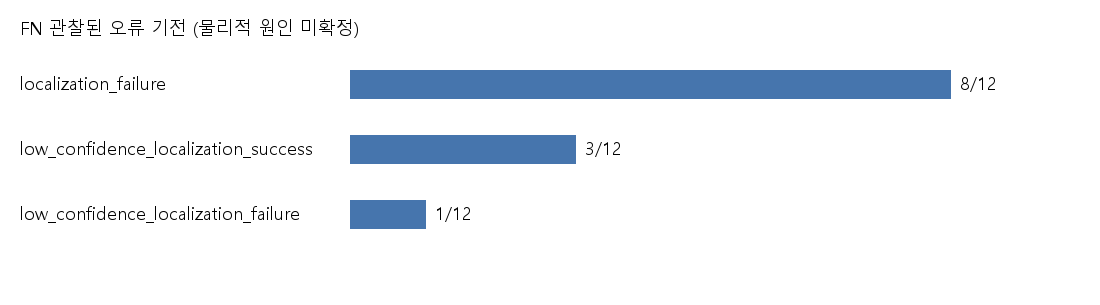

출처: outputs/error_analysis/summary/fn_cause_frequency.png
기존 FP 빈도 그래프


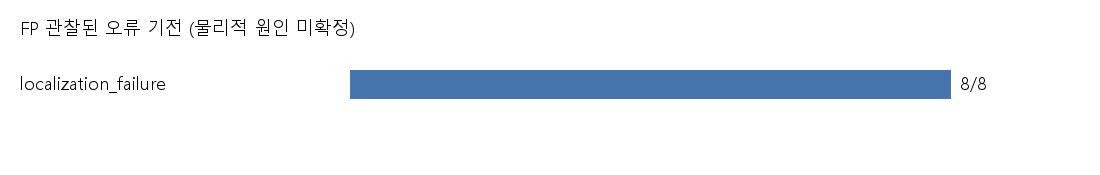

출처: outputs/error_analysis/summary/fp_cause_frequency.png
별도 보조 분석: FN9/12에 저점수 IoU≥0.5 후보 존재; 주 분류는8/3/1 유지


,case_id,cause,low_confidence_confidence,low_confidence_gt_iou
0,U0138_FN_gt0,low_confidence_localization_success,0.191274,0.771798
1,U0147_FN_gt0,localization_failure,0.026449,0.519733
2,U0147_FN_gt1,localization_failure,0.019049,0.854624
6,U0303_FN_gt0,localization_failure,0.043499,0.681132
7,U0303_FN_gt2,localization_failure,0.028650,0.765269
10,U0352_FN_gt0,low_confidence_localization_success,0.023290,0.690004
13,U0371_FN_gt2,localization_failure,0.013438,0.508803
17,U0380_FN_gt0,low_confidence_localization_success,0.097960,0.746874
18,U0488_FN_gt0,localization_failure,0.010918,0.586175


In [11]:
error_cases=load_csv('outputs/error_analysis/error_cases.csv')
classification=load_csv('outputs/error_analysis/error_classification.csv')
cause_frequency=load_csv('outputs/error_analysis/summary/cause_frequency.csv')
fn_diagnostics=load_csv('outputs/error_analysis/summary/fn_candidate_diagnostics.csv')
gt_conditions=load_csv('outputs/error_analysis/summary/gt_condition_rates.csv')
all_gt=load_csv('outputs/error_analysis/summary/all_test_gt.csv')
fp_confidence=load_csv('outputs/error_analysis/summary/fp_confidence_bins.csv')
verification=load_json('outputs/error_analysis/summary/verification.json')
assert set(error_cases['unique_id']).issubset(split_ids['test'])
assert set(classification['unique_id']).issubset(split_ids['test'])
assert set(all_gt['unique_id']) == split_ids['test']
assert len(all_gt) == 160
assert all_gt.groupby('unique_id').size().sort_index().equals(
    manifest.loc[manifest['split']=='test'].set_index('unique_id')['bbox_count'].sort_index())
assert (all_gt['status']=='FN').sum() == 12 and (all_gt['status']=='TP').sum() == 148
assert set(fn_diagnostics['case_id']) == set(error_cases.loc[error_cases['error_type']=='FN', 'case_id'])
print('오류 분석: Test 76장 / GT 160개 / TP 148개 / FN 12개 / FP 8개')
fn=error_cases[error_cases.error_type=='FN'].copy()
fp=error_cases[error_cases.error_type=='FP'].copy()
expected_causes={'localization_failure':8,'low_confidence_localization_success':3,'low_confidence_localization_failure':1}
assert len(fn)==12 and len(fp)==8 and fn.cause.value_counts().to_dict()==expected_causes
assert verification['candidate_iou_verified']
display(cause_frequency)
display(fn_diagnostics[['case_id','prediction_index','confidence','candidate_confidence_threshold',
        'candidate_gt_iou','best_eligible_iou','cause']])
display(fp[['case_id','confidence','candidate_gt_iou','prediction_to_gt_area_ratio','cause','review_required']])
show_png('outputs/error_analysis/summary/fn_cause_frequency.png','기존 수정 완료 FN 빈도 그래프')
show_png('outputs/error_analysis/summary/fp_cause_frequency.png','기존 FP 빈도 그래프')
auxiliary_low_score = fn[(fn['low_confidence_gt_iou'] >= .5) &
                         (fn['low_confidence_confidence'] < locked_policy['selected']['T_low'])]
assert len(auxiliary_low_score)==9 and fn['unique_id'].nunique()==8
print('별도 보조 분석: FN9/12에 저점수 IoU≥0.5 후보 존재; 주 분류는8/3/1 유지')
display(auxiliary_low_score[['case_id','cause','low_confidence_confidence','low_confidence_gt_iou']])

,condition,group,GT,FN,rate
0,small_object,True,41,7,0.170732
1,small_object,False,119,5,0.042017
2,low_contrast,True,60,7,0.116667
3,low_contrast,False,100,5,0.050000
4,image_edge_near,True,0,0,NaN
5,image_edge_near,False,160,12,0.075000
6,product_edge,True,73,3,0.041096
7,product_edge,False,87,9,0.103448
8,restoration_near,True,160,12,0.075000
9,restoration_near,False,0,0,NaN


기존 조건별 FN/GT 비교 그래프


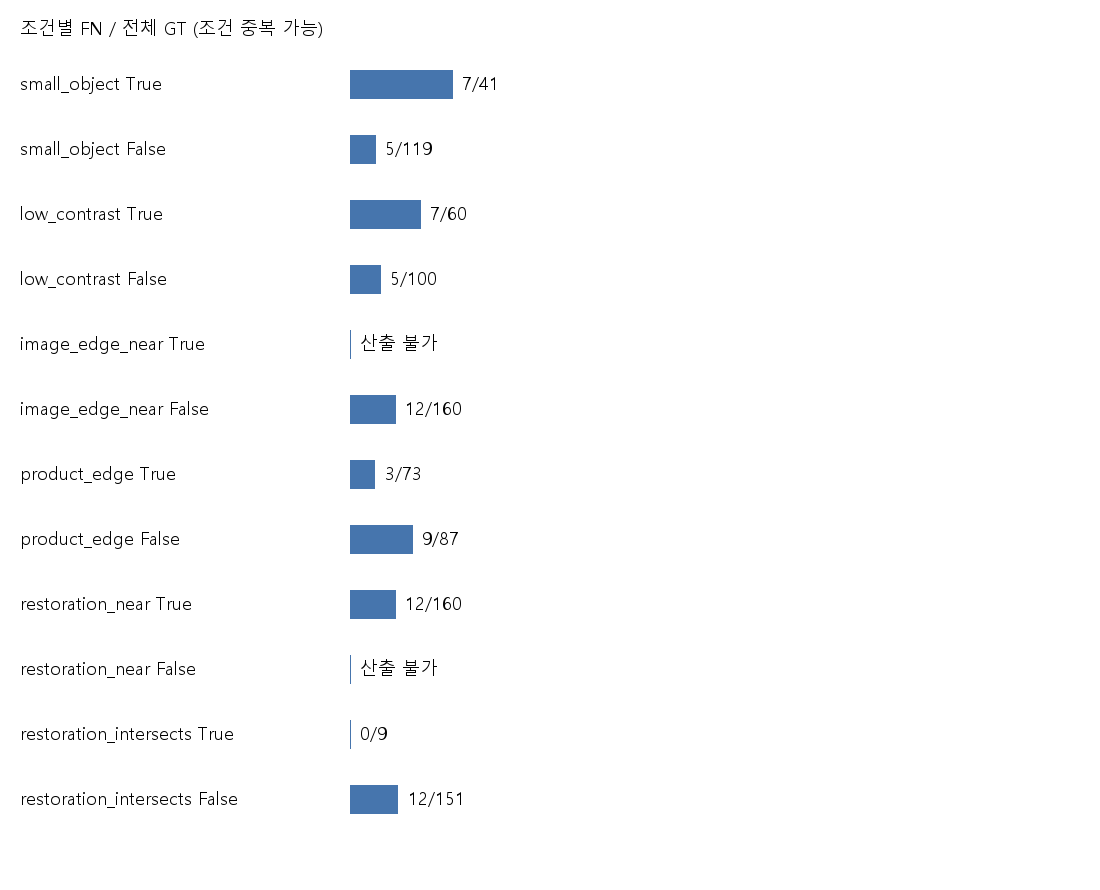

출처: outputs/error_analysis/summary/fn_condition_rates.png
크기 × 대비의 조건 조합 (재학습 또는 정책 선택에 사용하지 않은 기술 통계)


,small_object,low_contrast,GT,FN,FN_rate
0,False,False,78,1,0.012821
1,False,True,41,4,0.097561
2,True,False,22,4,0.181818
3,True,True,19,3,0.157895


설비별 FN/GT (인과 원인 해석 불가)


,machine,GT,FN,FN_rate
0,1,72,3,0.041667
1,2,28,1,0.035714
2,3,60,8,0.133333


,lower,upper,detections,FP,FP_fraction,fraction_of_all_FP
0,0.200000,0.500000,28,0,0.000000,0.000000
1,0.500000,0.700000,105,7,0.066667,0.875000
2,0.700000,1.000000,23,1,0.043478,0.125000


기존 confidence 구간별 FP/전체 예측


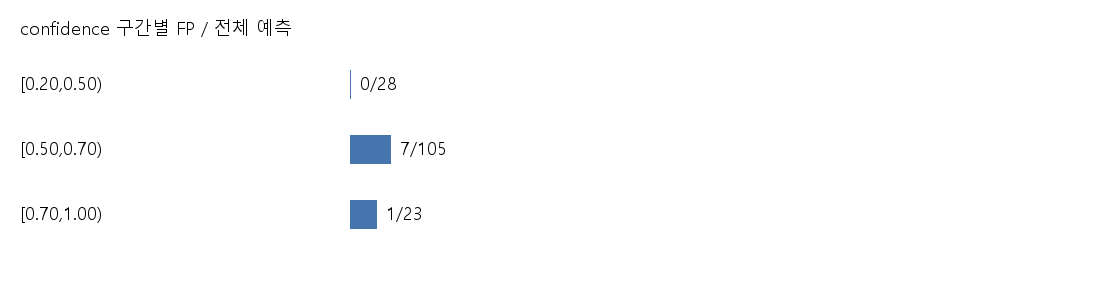

출처: outputs/error_analysis/summary/fp_confidence_bins.png


In [12]:
for condition, field in [('small_object','small_object'), ('low_contrast','low_contrast')]:
    saved_groups = gt_conditions[gt_conditions['condition'] == condition]
    for _, group in saved_groups.iterrows():
        selected_gt = all_gt[all_gt[field] == (str(group['group']).lower() == 'true')]
        assert len(selected_gt) == int(group['GT'])
        assert int((selected_gt['status'] == 'FN').sum()) == int(group['FN'])
        assert math.isclose(float(group['rate']), int(group['FN']) / int(group['GT']), rel_tol=1e-9)
display(gt_conditions[gt_conditions.condition.isin(['small_object','low_contrast','product_edge',
        'image_edge_near','restoration_near','restoration_intersects'])])
show_png('outputs/error_analysis/summary/fn_condition_rates.png','기존 조건별 FN/GT 비교 그래프')
print('크기 × 대비의 조건 조합 (재학습 또는 정책 선택에 사용하지 않은 기술 통계)')
interaction=all_gt.groupby(['small_object','low_contrast'],dropna=False).agg(
    GT=('status','size'),FN=('status',lambda x:(x=='FN').sum())).reset_index()
interaction['FN_rate']=interaction['FN']/interaction['GT']
display(interaction)
print('설비별 FN/GT (인과 원인 해석 불가)')
machine_condition=all_gt.groupby('machine').agg(GT=('status','size'),FN=('status',lambda x:(x=='FN').sum())).reset_index()
machine_condition['FN_rate']=machine_condition['FN']/machine_condition['GT']
display(machine_condition)
display(fp_confidence)
show_png('outputs/error_analysis/summary/fp_confidence_bins.png','기존 confidence 구간별 FP/전체 예측')


**Test 76장·GT 160개에서 관찰한 집중 조건과 한계:** Train 하위 25% 기준 소형 bbox≤81px²는 FN 7/41(17.07%), 그 외 5/119(4.20%)다.  
Train에서 저장된 기준으로 분류한 낮은 bbox 주변 정규화 대비≤0.0698918은 FN 7/60(11.67%), 그 외 5/100(5.00%)다.  
**관찰됨:** 소형 객체 전체와 저대비 객체 전체는 각각 비교군보다 높은 FN 비율을 보였다.  
그러나 소형+저대비는 **3/19=15.79%**, 소형+비저대비는 **4/22=18.18%**로, **소형군 내부에서는 저대비의 추가 위험 증가가 확인되지 않았다**.  
두 조건이 결합되면 위험이 더 증가한다는 결론은 내리지 않는다.  
소형·저대비 기준은 저장된 Train 특성 집계 816개에서 정한 기준이다.  
Train 전체 GT 828개와 기준 설정에 사용된 816개를 구분하며, Test를 보고 기준을 다시 정하지 않는다.  
이 두 조건은 중복되며 표본·설비·제품 구조가 얽혀 있으므로 두 조건의 인과관계나 독립적인 효과를 단정하지 않는다.  
기존 조합표는 기술 통계로만 해석한다.  
제품 경계군 FN 3/73(4.11%)은 비경계 9/87(10.34%)보다 낮아 이번 Test에서 경계 집중을 주장하지 않는다.  
모든 GT가 복원 영역 5px 이내라 비근접 비교군이 없으며, 복원 원인 집중을 주장할 수 없다.  
FP 8개는 모두 FN이 있는 4개 이미지에서 미검출 GT와 겹치지만 IoU 0.5를 통과하지 못한다.  
7개는 예측 면적이 GT보다 크고, U0488은 중심 이동이 관찰된다.  
소형/저대비는 측정 조건이고 주 오류 기전·물리적 원인과 구분한다.  
전 사례는 전문가 bbox/라벨 검토가 필요하다.


### 7.1 위치는 맞지만 점수가 낮은 FN

**목적:** U0138/U0352/U0380의 candidate IoU≥0.5와 confidence<0.20을 함께 확인한다.  
**공식 평가항목 연결:** 3. 영향요인 및 오류분석.  

각각 IoU≈0.771798/0.690004/0.746874, confidence≈0.191274/0.023290/0.097960이며  
`low_confidence_localization_success`다.  
위치 통과는 low-confidence 후보의 진단 결과이고 평가 TP로 전환하지 않는다.  
U0181의 기존 최고 IoU candidate는 IoU≈0.365997, confidence≈0.001634로 점수와 위치 기준 모두 미달이다.


,case_id,confidence,candidate_gt_iou,best_eligible_iou,cause
0,U0138_FN_gt0,0.191274,0.771798,0.000000,low_confidence_localization_success
3,U0181_FN_gt0,0.001634,0.365997,0.000000,low_confidence_localization_failure
6,U0352_FN_gt0,0.023290,0.690004,0.000000,low_confidence_localization_success
10,U0380_FN_gt0,0.097960,0.746874,0.000000,low_confidence_localization_success


U0138_FN_gt0 / 기존 개별 분석 이미지


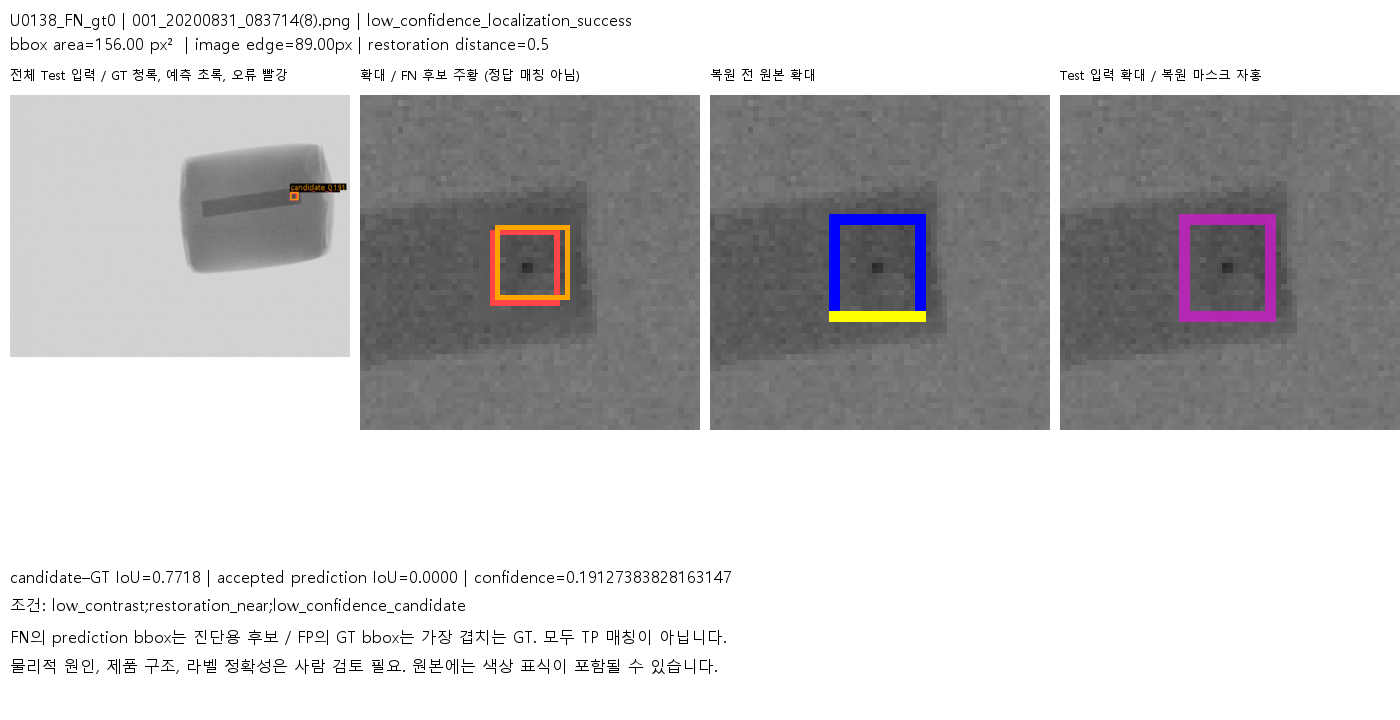

출처: outputs/error_analysis/fn/U0138_FN_gt0.png
U0352_FN_gt0 / 기존 개별 분석 이미지


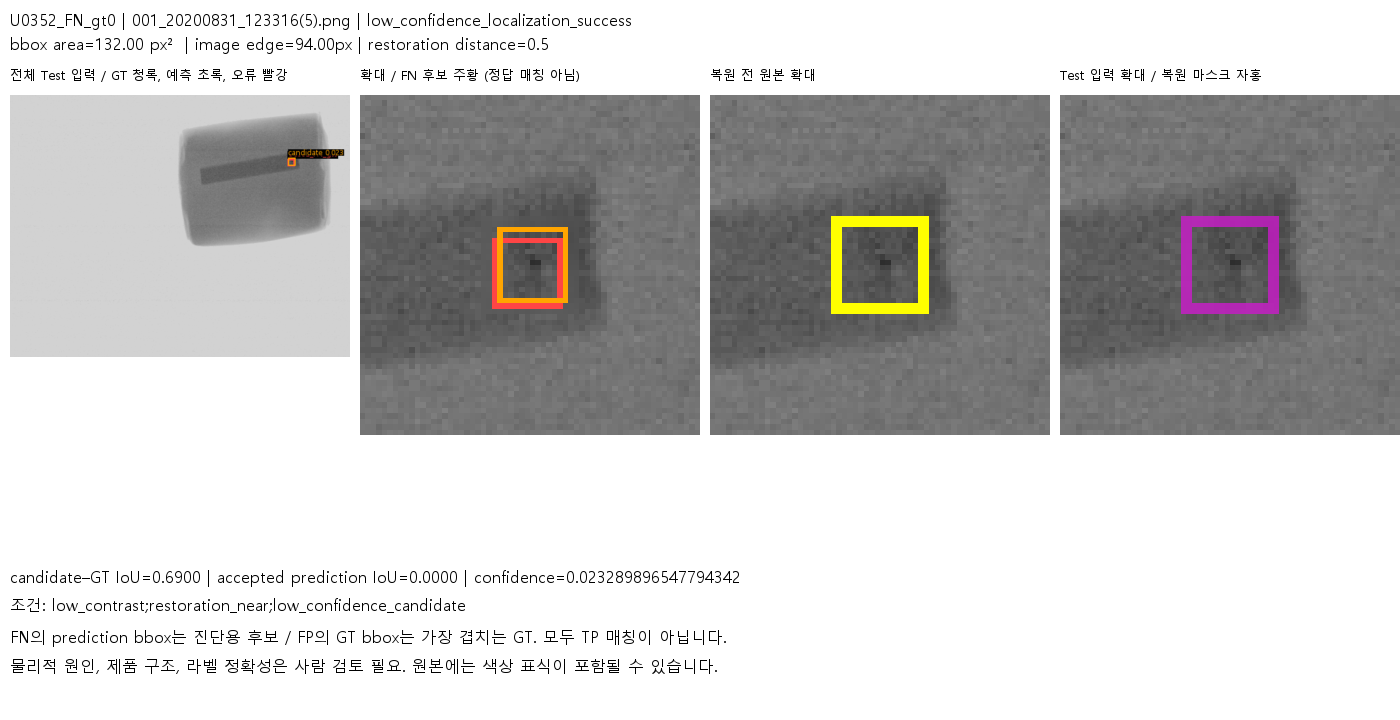

출처: outputs/error_analysis/fn/U0352_FN_gt0.png
U0380_FN_gt0 / 기존 개별 분석 이미지


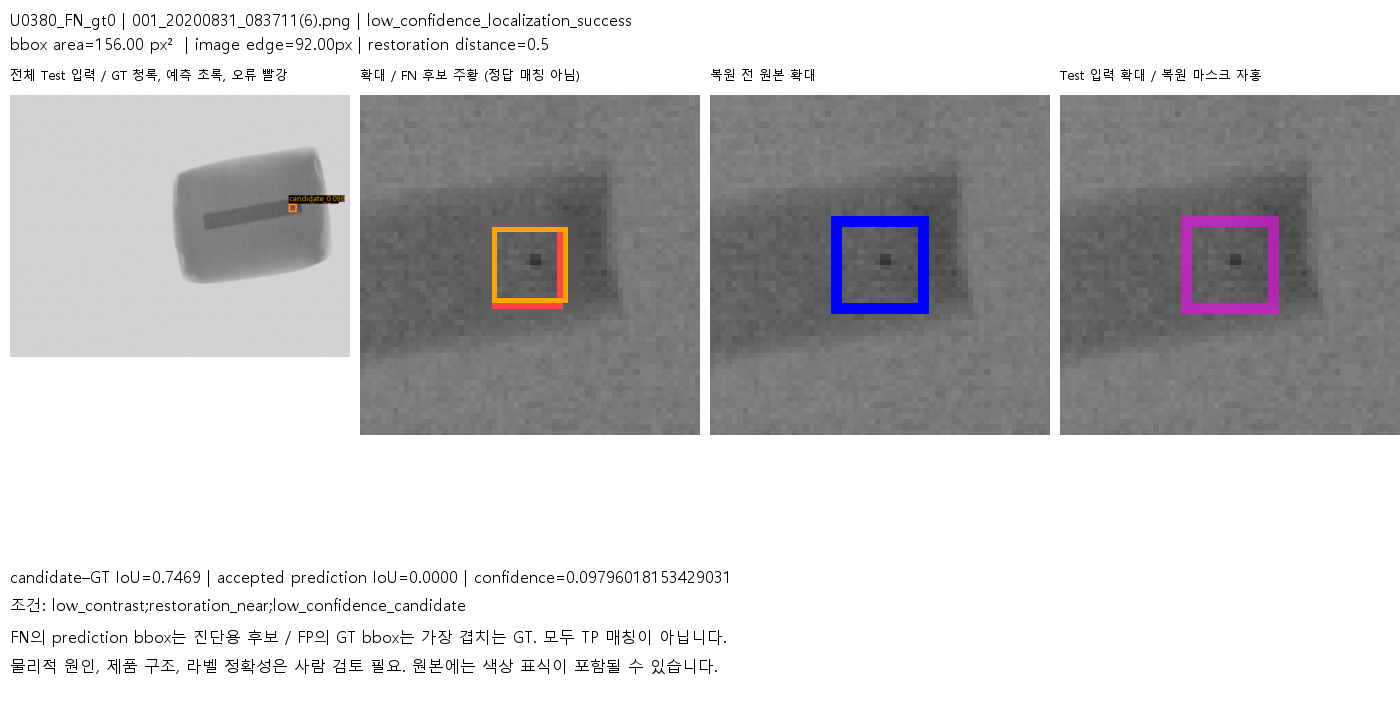

출처: outputs/error_analysis/fn/U0380_FN_gt0.png
U0181_FN_gt0 / 기존 개별 분석 이미지


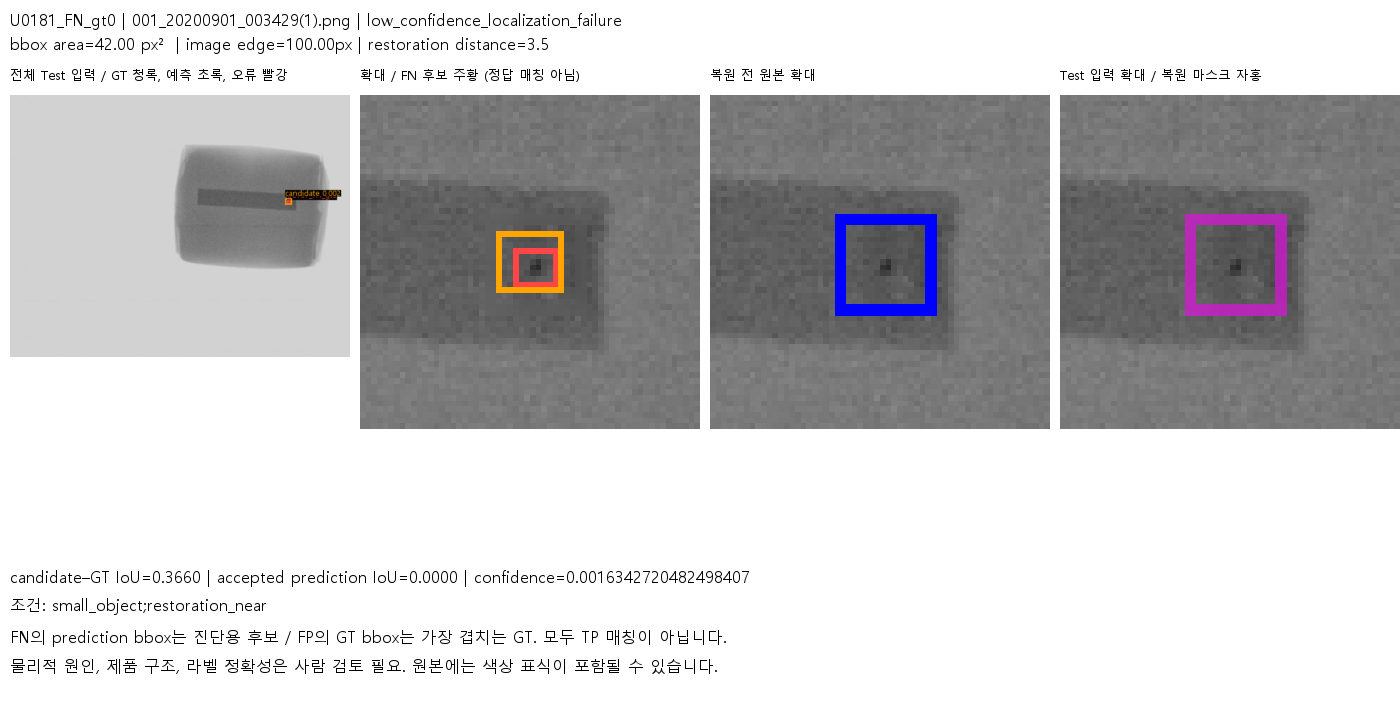

출처: outputs/error_analysis/fn/U0181_FN_gt0.png


In [13]:
selected_ids=['U0138_FN_gt0','U0352_FN_gt0','U0380_FN_gt0','U0181_FN_gt0']
display(fn_diagnostics[fn_diagnostics.case_id.isin(selected_ids)]
        [['case_id','confidence','candidate_gt_iou','best_eligible_iou','cause']])
for case_id in selected_ids:
    show_png(f'outputs/error_analysis/fn/{case_id}.png',case_id+' / 기존 개별 분석 이미지')


### 7.2 위치/크기 오차와 IoU 경계 사례

**목적:** FN과 FP가 같은 물체의 bbox 오차로 동시에 발생할 수 있음을 확인한다.  
**공식 평가항목 연결:** 3. 영향요인 및 오류분석.  

U0488의 confidence≈0.590495는 threshold 이상이지만 IoU **0.498477**로 0.5에 근소하게 미달한다.  
따라서 GT는 FN, 대응 accepted prediction은 FP로 기록된다.  
이를 ‘탐지가 전혀 없음’ 또는 ‘정상 구조 오인’으로 단정하지 않는다.  
U0371의 3개 작은 GT도 대응 예측 bbox가 더 넓어 IoU 기준을 놓친다.  
Test를 보고 IoU 기준을 낮추거나 threshold를 재조정하지 않는다.


,case_id,error_type,confidence,candidate_gt_iou,cause,bbox_area,gt_area_ratio
11,U0371_FN_gt0,FN,0.657017,0.306915,localization_failure,30.000000,0.000257
12,U0371_FN_gt1,FN,0.635512,0.252222,localization_failure,28.000000,0.000240
13,U0371_FN_gt2,FN,0.647065,0.356296,localization_failure,35.000000,0.000299
14,U0371_FP_pred0,FP,0.657017,0.306915,localization_failure,97.746974,0.000257
15,U0371_FP_pred1,FP,0.647065,0.356296,localization_failure,98.233057,0.000299
16,U0371_FP_pred2,FP,0.635512,0.252222,localization_failure,111.013335,0.000240
18,U0488_FN_gt0,FN,0.590495,0.498477,localization_failure,121.000000,0.001153
19,U0488_FP_pred0,FP,0.590495,0.498477,localization_failure,106.608347,0.001153


U0488 FN / IoU0.498477


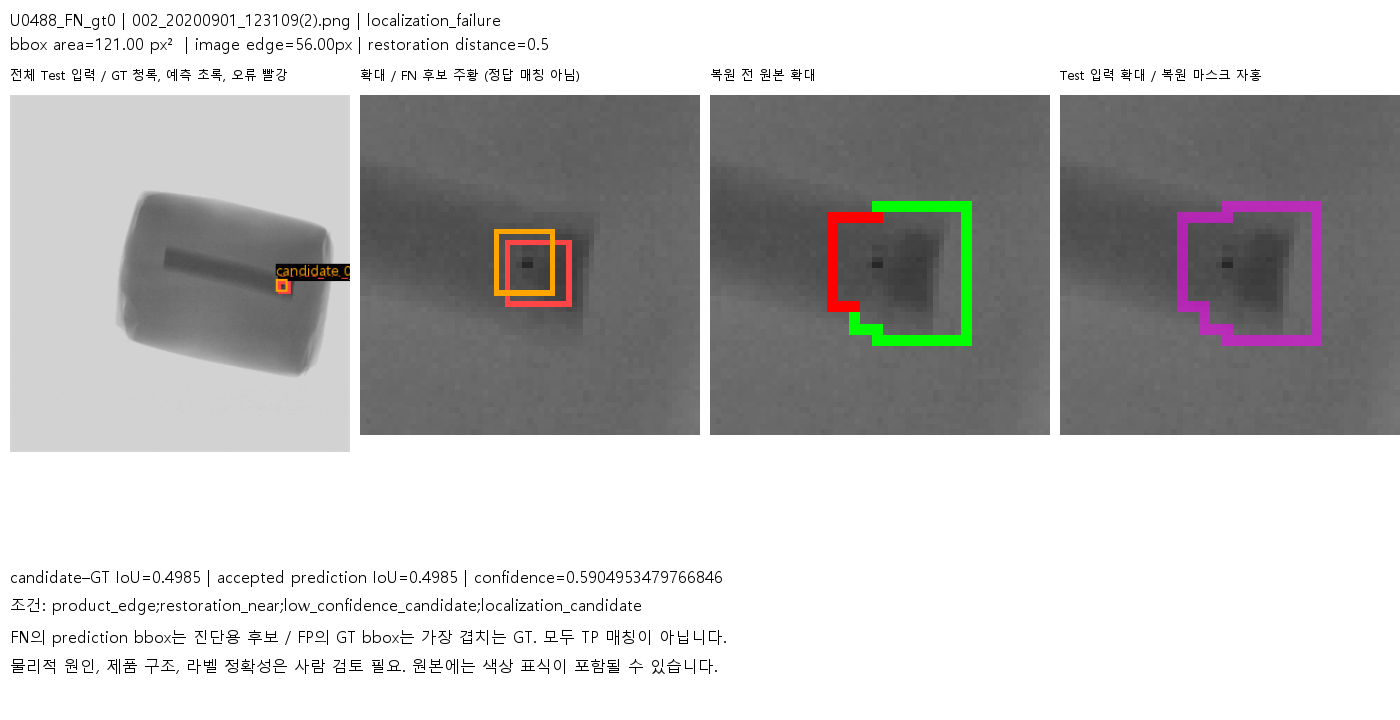

출처: outputs/error_analysis/fn/U0488_FN_gt0.png
U0488 FP / 같은 IoU 기준 미달


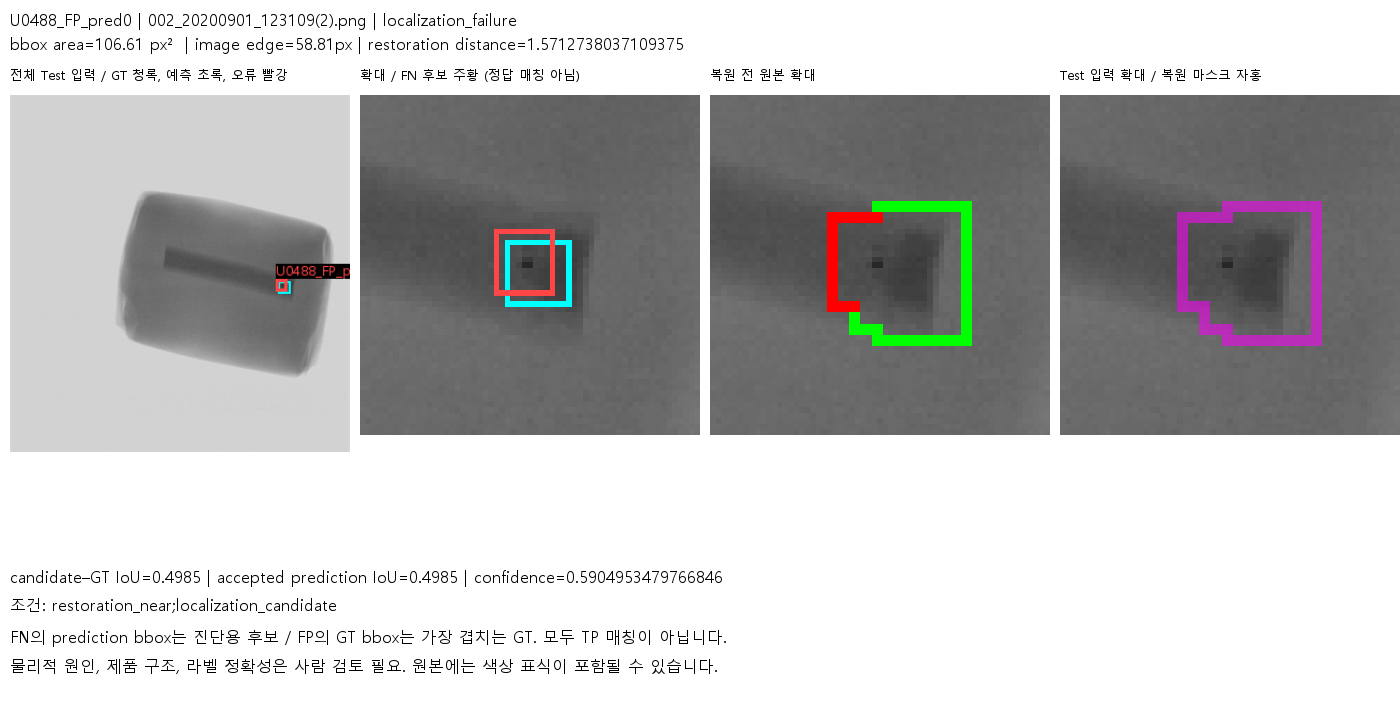

출처: outputs/error_analysis/fp/U0488_FP_pred0.png
U0371의 소형 GT 대응 FP 대표


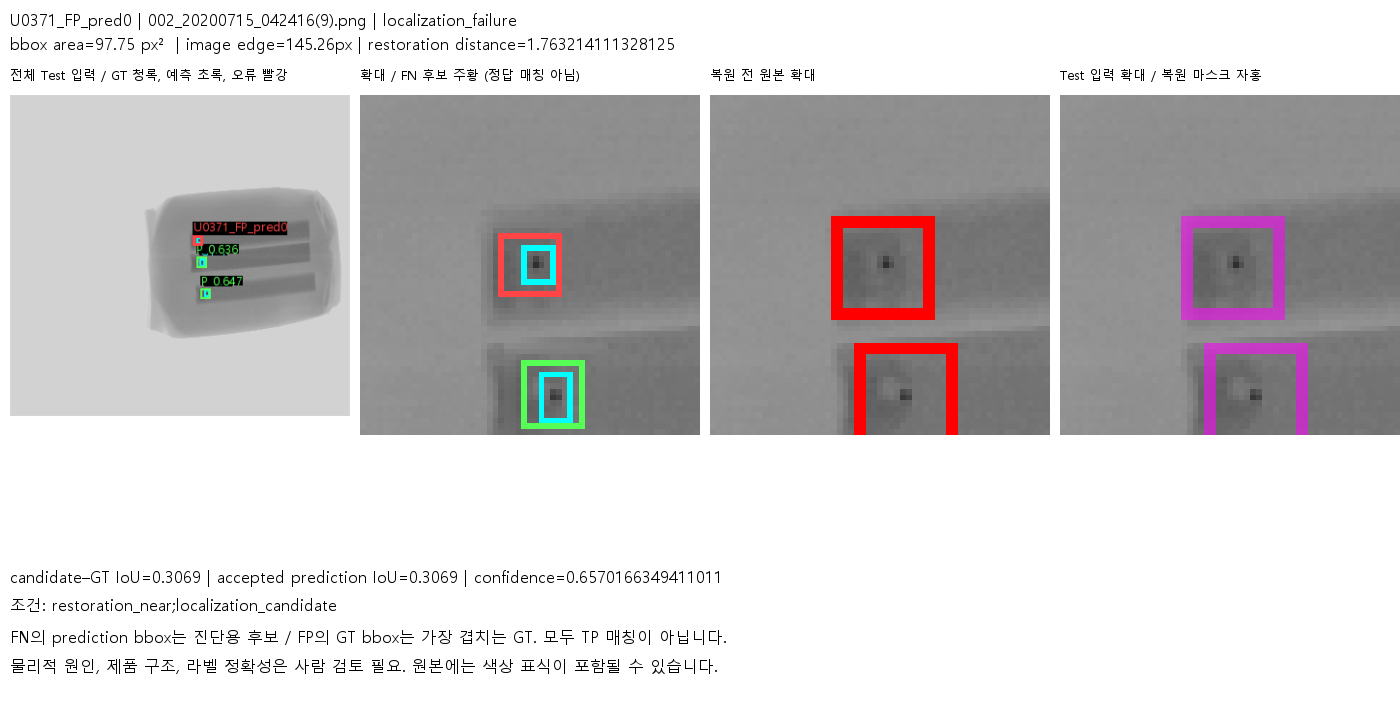

출처: outputs/error_analysis/fp/U0371_FP_pred0.png
사람 검토 대상:


,case_id,image_name,cause,review_required,physical_cause
0,U0138_FN_gt0,001_20200831_083714(8).png,low_confidence_localization_success,True,unknown
1,U0147_FN_gt0,001_20200622_203305(8).png,localization_failure,True,unknown
2,U0147_FN_gt1,001_20200622_203305(8).png,localization_failure,True,unknown
3,U0147_FP_pred0,001_20200622_203305(8).png,localization_failure,True,unknown
4,U0147_FP_pred2,001_20200622_203305(8).png,localization_failure,True,unknown
5,U0181_FN_gt0,001_20200901_003429(1).png,low_confidence_localization_failure,True,unknown
6,U0303_FN_gt0,001_20200622_203316(0).png,localization_failure,True,unknown
7,U0303_FN_gt2,001_20200622_203316(0).png,localization_failure,True,unknown
8,U0303_FP_pred1,001_20200622_203316(0).png,localization_failure,True,unknown
9,U0303_FP_pred2,001_20200622_203316(0).png,localization_failure,True,unknown


In [14]:
display(error_cases[error_cases.unique_id.isin(['U0488','U0371'])][
        ['case_id','error_type','confidence','candidate_gt_iou','cause','bbox_area','gt_area_ratio']])
show_png('outputs/error_analysis/fn/U0488_FN_gt0.png','U0488 FN / IoU0.498477')
show_png('outputs/error_analysis/fp/U0488_FP_pred0.png','U0488 FP / 같은 IoU 기준 미달')
show_png('outputs/error_analysis/fp/U0371_FP_pred0.png','U0371의 소형 GT 대응 FP 대표')
print('사람 검토 대상:')
display(error_cases[['case_id','image_name','cause','review_required','physical_cause']])


## 8. 512장 분석 결과에 기반한 현장 활용 제안

**목적:** bbox·confidence와 오류분석을 작업자 재검, AI 보조 판정, 품질 이력관리 흐름으로 연결한다.  
**공식 평가항목 연결:** 4. 현장 활용방안, 3. 영향요인 및 오류분석, 5. 창의성·차별성.  

512장 데이터는 모두 결함 라벨을 포함하며, 아래 제안은 Test 76장의 오류 관찰을 참고한다.  
양품이 포함된 실제 생산 데이터에서 경보 품질과 작업자 재검 효과를 추가 검증해야 한다.  

**제안됨: 현장 활용 흐름 (실제 운영 효과 검증과 구분)**  

X-ray 입력 → 전처리 → AI 이물질 탐지 → bbox + confidence 출력 → 고신뢰 후보 우선 확인 → 저신뢰 후보 재검 → 소형/저대비 위험조건 추가 확인 → 작업자 최종판정 → 결과 저장  

전처리는 기존 컬러 주석이 있을 때 적용하며, 실센서 영상에 표시가 없다면 불필요한 복원을 추가하지 않는다.  
이미지 단위 잠긴 정책은 하나라도 confidence≥0.25면 자동 NG 후보, high가 없고 0.20≤confidence<0.25면 재검 후보, 둘 다 없으면 정상 후보다.  
이는 AI 경보/검사 우선순위이며 최종 출하 판정은 작업자가 원본·확대 영상과 제품 기준으로 결정한다.  
하나의 이미지에 high 후보가 있더라도 저점수 bbox와 소형/저대비 위치를 추가 확인할 수 있다.  
U0352/U0380처럼 0.20보다 낮은 후보는 현재 band 정책으로 복구되지 않는다.  
모든 낮은 점수를 자동 통과/자동 NG 처리하는 것은 별도 검증 없이 제안하지 않는다.  
소형/저대비 진단은 GT 기반으로 계산한 조건이므로 실운영 후보 bbox feature의 TP/FP 구분력과 같다고 가정하지 않는다.  

**검증됨/관찰됨:** 저장 결과에서 잠긴 T_low=0.20/T_high=0.25의 screening·이미지 routing 정책과 Test 집계를 확인했다.  
이는 저장 결과 분석이며 현장 시스템 배포나 실제 작업자 재검 효과의 검증이 아니다.  
**제안됨·미구현:** score<0.20 후보 재검은 현재 구현된 정책이 아닌 운영 제안이다.  
저점수 후보를 현장 화면으로 제공하고 재검을 연결하는 추가 기능과 효과는 미구현/미검증 상태다.  
**작업자 참고 조건·자동판정 미구현:** GT 기반 소형/저대비 조건은 오류분석에서 도출한 작업자 참고 조건이다.  
GT 없는 실제 운영 자동판정 기능으로 구현되거나 검증되지 않았다.  
작업자 최종판정과 품질 이력관리도 현장 적용 제안으로 구분한다.


In [15]:
field_use = pd.DataFrame([
    ['입력/전처리','원본, 표시 유무, 기존 mask, 처리 버전','주석 shortcut 예방·원본 보존','전처리 보존성 비교와 연결','기존 처리 검증됨; 현장 적용 제안됨'],
    ['고신뢰 후보 우선 확인','bbox와 점수≥0.25','자동 NG 후보 경보 후 작업자 확인','U0488의 고점수 위치 오차도 확인','저장 routing 검증됨; 작업자 흐름 제안됨'],
    ['저신뢰 후보 재검','0.20≤점수<0.25 band 및 확대 영상','고신뢰가 없을 때 이미지 재검 후보','Test band0이므로 개선 미검증','기존 정책 분석됨; 현장 재검 제안됨'],
    ['위치 일치/저점수 점검','점수<0.20의 진단 후보·제품 검사 기준','결함 가능성 추가 검토','U0138/U0352/U0380; 자동 복구 주장 아님','운영 제안됨; 정책 확장 미구현'],
    ['소형/저대비 추가 확인','확대·주변 대비·제품 구조','작업자 참고 조건','Test GT 기준: 소형17.07%, 저대비11.67%','오류조건 관찰됨; 자동판정 미구현'],
    ['bbox 위치/크기 검토','GT 검증 자료, 원본/표시 영상','과대 bbox·IoU 경계 원인 점검','FP8/8와 선택 candidate FN8/12','IoU 검증됨; 현장 확인 제안됨'],
    ['최종판정/품질 이력','작업자 판정, 설비/serial/시간, 모델/threshold 버전','이력 조회·설비/제품별 오류 모니터링','자동 NG 후보와 실제 판정·재검 결과 분리','현장 기능 제안됨·미구현'],
], columns=['단계','확인 정보','활용','오류분석 연결','상태'])
display(field_use)
display(pd.DataFrame([
    ['경보 품질','양품/불량 모두 포함한 신규 독립 생산 데이터','false reject, 미검출 이미지율, 작업자 재검 정확도'],
    ['운영 부하','실제 검사시간·작업자 referral 기록','재검률, cycle time, 검사 우선순위 효율'],
    ['공정점검','설비·제품·촬영조건별 품질 이력','오류 발생 조건 변화 모니터링; 원인 단정 금지'],
],columns=['확인 대상','추가 검증 자료','지표']))

,단계,확인 정보,활용,오류분석 연결,상태
0,입력/전처리,"원본, 표시 유무, 기존 mask, 처리 버전",주석 shortcut 예방·원본 보존,전처리 보존성 비교와 연결,기존 처리 검증됨; 현장 적용 제안됨
1,고신뢰 후보 우선 확인,bbox와 점수≥0.25,자동 NG 후보 경보 후 작업자 확인,U0488의 고점수 위치 오차도 확인,저장 routing 검증됨; 작업자 흐름 제안됨
2,저신뢰 후보 재검,0.20≤점수<0.25 band 및 확대 영상,고신뢰가 없을 때 이미지 재검 후보,Test band0이므로 개선 미검증,기존 정책 분석됨; 현장 재검 제안됨
3,위치 일치/저점수 점검,점수<0.20의 진단 후보·제품 검사 기준,결함 가능성 추가 검토,U0138/U0352/U0380; 자동 복구 주장 아님,운영 제안됨; 정책 확장 미구현
4,소형/저대비 추가 확인,확대·주변 대비·제품 구조,작업자 참고 조건,"Test GT 기준: 소형17.07%, 저대비11.67%",오류조건 관찰됨; 자동판정 미구현
5,bbox 위치/크기 검토,"GT 검증 자료, 원본/표시 영상",과대 bbox·IoU 경계 원인 점검,FP8/8와 선택 candidate FN8/12,IoU 검증됨; 현장 확인 제안됨
6,최종판정/품질 이력,"작업자 판정, 설비/serial/시간, 모델/threshold 버전",이력 조회·설비/제품별 오류 모니터링,자동 NG 후보와 실제 판정·재검 결과 분리,현장 기능 제안됨·미구현


,확인 대상,추가 검증 자료,지표
0,경보 품질,양품/불량 모두 포함한 신규 독립 생산 데이터,"false reject, 미검출 이미지율, 작업자 재검 정확도"
1,운영 부하,실제 검사시간·작업자 referral 기록,"재검률, cycle time, 검사 우선순위 효율"
2,공정점검,설비·제품·촬영조건별 품질 이력,오류 발생 조건 변화 모니터링; 원인 단정 금지


## 9. 최종 결론 — 512장 분석과 Test 평가

**공식 평가항목 연결:** 1–6 전체.  

1. 본 분석은 고유 이미지 **512장·결함 bbox 1,163개**를 대상으로 한다.  
   설비·제품·촬영일의 45개 그룹을 보존해 **Train 359장/828개, Val 77장/175개, Test 76장/160개**로 분할했다.  
   라벨 누락·형식 오류·동일 이미지의 split 누출은 0건이다.  
   원본 출처 감사와 제출 라벨 검증에서 선택 라벨 512/512장이 일치했다.  
   과거 XML–YOLO 차이 이력 23장도 최종 선택한 canonical TXT와 모두 일치한다.  
   출처 차이 이력과 현재 선택 라벨의 일치 상태를 구분하며 유사쌍 검토는 별도 사항이다.  
2. 최종 512장에는 TELEA/radius 3/dilation 0을 적용했다.  
   복원 mask와 겹치는 GT는 91장·141개 bbox이며 mask 밖 변경 픽셀은 0이다.  
   변경 범위 검사는 결함 신호의 완전 보존 증명과 구분한다.  
3. 전처리 선택과 Fake Restoration 진단의 **기존 20장 PoC는 보조 근거**다.  
   해당 진단에서 fake FP와 GT loss/gain은 0이었지만, 이를 최종 512장 모델의 shortcut 부재로 해석하지 않는다.  
4. 모델 비교는 같은 359/77/76 분할의 완료 실험 11개와 YOLO11n·YOLOv8n 두 구조를 포함한다.  
   기본 증강·640 조건에서 Val은 YOLOv8n, Test는 YOLO11n이 네 지표 모두 높았다.  
   감마·노이즈의 일관된 성능 개선은 확인되지 않았다.  
   고정 최종 모델의 Val F1은 0.969879, lr0.0005 설정의 F1은 0.971176이다.  
   최종 모델은 F1 최대 모델이 아니며 Recall·Val mAP50–95와 후속 분석 연결을 고려한 사후 설명으로 유지한다.  
   Test를 이용해 재선택하지 않는다.  
5. **Val 77장·GT 175개**로 정한 T_low=0.20/T_high=0.25 정책은 Val에서 FN 1개 감소·FP 1개 증가를 보였다.  
   **Test 76장·GT 160개**에서는 TP 148/FN 12/FP 8, Precision 94.87%, Recall 92.50%, F1 약 93.67%이며 baseline 대비 개선이 없었다.  
   0.20은 F1 최적값이 아닌 screening 하한이다.  
6. Test의 FN 12건은 8개 이미지에서 발생했다.  
   선택 candidate 기준 분류는 위치 실패 8건, 저점수 위치 성공 3건, 저점수 위치 실패 1건이다.  
   다른 후보를 포함하면 FN 9/12에 저점수 IoU≥0.5 후보가 존재한다.  
   두 결과는 같은 FN을 다른 관점에서 진단한 것으로 합산하지 않는다.  
7. Test 내부 조건별 FN/GT는 소형 7/41(17.07%), 저대비 7/60(11.67%)였다.  
   소형군 내 저대비 3/19(15.79%)는 비저대비 4/22(18.18%)보다 낮았다.  
   512장 전체의 오류율이나 조건 간 인과관계로 확대하지 않는다.  
8. U0138/U0352/U0380은 위치가 맞는 저점수 후보가 있고, U0488은 IoU 0.498477의 경계 사례다.  
   작업자가 점수·위치·확대 영상을 함께 확인하도록 돕는 근거가 된다.  
9. 현장 검사·판정·이력 관리와 score<0.20 추가 재검은 제안 단계다.  
   512장 모두 결함 라벨을 포함하므로 실제 생산 불량률·양품 오경보율·운영 개선 효과는 별도 생산 데이터에서 검증해야 한다.


## KAMP 공식 평가항목 대응표 — 512장 기준

512장의 데이터 구성, 동일 분할 모델 비교, Val 정책 선택, Test 오류 분석과 현장 활용 제안을 평가항목 1–6에 연결한다.  
20장 보조 실험은 전처리·shortcut 진단의 제한된 근거로 구분한다.  
동일 조건의 YOLOv8n·YOLO11n 구조 비교를 포함한다.  
앙상블·확률보정·불균형 학습과 반복 seed 검증은 수행하지 않았다.


In [16]:
kamp_mapping = pd.DataFrame([
    ['1. 데이터 이해 및 진단','1, 2, 3','최종 512장의 생산단위/변수, 시간·설비·제품 구성, 결측·중복·라벨·bbox 분포, 그룹 분할, 표시 제거',
     '512장 메타데이터·1,163 bbox / 원본 라벨 출처 감사 / split_summary / 910 유사쌍 QA','선택 라벨 512/512 출처 일치; 유사쌍·bbox 의미 검토는 별도'],
    ['2. AI 예측모델 개발','1, 4, 5, 6','baseline 포함 모델 비교, Precision/Recall/F1/mAP, 고정 최종 모델, Val threshold',
     '동일 512장 YOLOv8n·YOLO11n 구조 비교 / 증강 비교 / Val77 정책 선택 / Test76 평가','구조 비교 조건 일치 확인; 단일 seed; 기존 후속 분석 모델 유지; F1 정의 분리'],
    ['3. 영향요인 및 오류분석','7, 7.1, 7.2','FN/FP 사례, 크기×대비 조합, 설비별 FN/GT, IoU·confidence 분리',
     'Test76·GT160 / FN12·FP8 / candidate IoU / 조건별 FN/GT','소표본·조건 중복; 물리적 원인 미확정'],
    ['4. 현장 활용방안','1, 6, 8','사전경보, 검사 우선순위, 저점수 재검, 작업자 보조판정, 공정점검·품질 이력',
     'bbox+점수+확대 원본 / 잠긴 이미지 routing / 최종판정 저장 흐름','실제 생산라인 개선은 추가 검증 필요'],
    ['5. 창의성·차별성','3, 4, 7, 8','palette 주석 제거, TELEA/NS 보존성 비교, Fake Restoration negative control, 제조 조건 결합',
     '512장 마킹 처리 / 20장 보조 paired 진단 / Test 조건별 작업자 확인 제안','앙상블·확률보정·불균형 학습은 미수행'],
    ['6. 코드 및 재현성','실행 준비(셀2), 5, 7, 코드 및 재현성(셀35–36)','실제 환경·requirements 차이, 필수 상대경로 파일, 위→아래 실행, 기존 bbox 재계산',
     '512장·split ID 연결 검사 / 출처 SHA / IoU 재계산 / Jupyter 전체 실행','커널 실행 결과는 verification.json 참조; SHA는 현재 입력 불변성 확인'],
],columns=['공식 평가항목','Notebook section','대응 내용','실제 근거','평가 시 구분할 한계'])
display(kamp_mapping)

,공식 평가항목,Notebook section,대응 내용,실제 근거,평가 시 구분할 한계
0,1. 데이터 이해 및 진단,"1, 2, 3","최종 512장의 생산단위/변수, 시간·설비·제품 구성, 결측·중복·라벨·bbox 분포, 그룹 분할, 표시 제거","512장 메타데이터·1,163 bbox / 원본 라벨 출처 감사 / split_summary / 910 유사쌍 QA",선택 라벨 512/512 출처 일치; 유사쌍·bbox 의미 검토는 별도
1,2. AI 예측모델 개발,"1, 4, 5, 6","baseline 포함 모델 비교, Precision/Recall/F1/mAP, 고정 최종 모델, Val threshold",동일 512장 YOLOv8n·YOLO11n 구조 비교 / 증강 비교 / Val77 정책 선택 / Test76 평가,구조 비교 조건 일치 확인; 단일 seed; 기존 후속 분석 모델 유지; F1 정의 분리
2,3. 영향요인 및 오류분석,"7, 7.1, 7.2","FN/FP 사례, 크기×대비 조합, 설비별 FN/GT, IoU·confidence 분리",Test76·GT160 / FN12·FP8 / candidate IoU / 조건별 FN/GT,소표본·조건 중복; 물리적 원인 미확정
3,4. 현장 활용방안,"1, 6, 8","사전경보, 검사 우선순위, 저점수 재검, 작업자 보조판정, 공정점검·품질 이력",bbox+점수+확대 원본 / 잠긴 이미지 routing / 최종판정 저장 흐름,실제 생산라인 개선은 추가 검증 필요
4,5. 창의성·차별성,"3, 4, 7, 8","palette 주석 제거, TELEA/NS 보존성 비교, Fake Restoration negative control, 제조 조건 결합",512장 마킹 처리 / 20장 보조 paired 진단 / Test 조건별 작업자 확인 제안,앙상블·확률보정·불균형 학습은 미수행
5,6. 코드 및 재현성,"실행 준비(셀2), 5, 7, 코드 및 재현성(셀35–36)","실제 환경·requirements 차이, 필수 상대경로 파일, 위→아래 실행, 기존 bbox 재계산",512장·split ID 연결 검사 / 출처 SHA / IoU 재계산 / Jupyter 전체 실행,커널 실행 결과는 verification.json 참조; SHA는 현재 입력 불변성 확인


## 코드 및 재현성 — KAMP 공식 평가항목6

**목적:** 표·이미지·모델 연결에 사용한 기존 결과의 상대경로와 SHA256을 제공하고 실행 중 변경이 없었는지 확인한다.  
**공식 평가항목 연결:** 6. 코드 및 재현성(1·2·5의 근거 추적 포함).  

**실행 환경·순서 — 검증됨:** 생성 환경은 Python3.12.14/pandas3.0.1/numpy2.3.5이고 Pillow를 사용했다.  
실제 현재 버전과 requirements.txt의 차이는 아래 표로 확인한다.  
모델 런타임을 호출하지 않으며 패키지를 설치하거나 requirements를 변경하지 않는다.  
제출 폴더에서 셀 1→36의 코드 셀 17개를 실제 Jupyter 커널로 실행하고 표·그림 출력을 저장했다.  
제출본의 Jupyter 커널 실행 검증 결과는 verification.json에 기록한다.  
실행 환경은 requirements-notebook.txt로 설치하고 이 제출 폴더에서 위→아래로 실행한다.  

**512장 연결 검증:** manifest의 고유 이미지 512장과 메타데이터 ID, 이미지별 bbox 개수, 359/77/76 분할의 ID 비중복, Test GT 160개의 이미지별 라벨 수, Val/Test 정책의 TP+FN 분모를 실행 중 확인한다.  
모델 비교는 저장된 이미지 수가 359/77/76인 실험으로 제한한다.  

**라벨 출처 재확인:** `scripts/audit_submission_label_consistency.py`로 프로젝트 원본 파일과 최종 라벨을 대조한 결과를 `outputs/submission_label_audit`에 저장했다.  
이 노트북에서는 제출 폴더에 포함된 512개 TXT의 실제 해시·형식·bbox 개수를 감사 기록과 다시 비교한다.  
원본 데이터셋이 없어도 제출 라벨의 감사 기록 연결을 재검증할 수 있다.  
과거 `previous_label_conflict`와 `UNREVIEWED`는 현재 출처 검증 결과와 구분한다.  

**필수 파일·상대경로:** 이 ipynb와 root 탐색용 train_yolo.py, requirements.txt, outputs/yolo_512_telea/manifest.csv·dataset.yaml·512개 TXT·라벨 출처 감사 CSV/JSON, clean_512 메타데이터/검증, clean_512_split 요약, 학습 run의 CSV·JSON·최종 best.pt, 전처리/shortcut/threshold/error_analysis 결과 및 참조 PNG가 필요하다.  
기존 predictions.json은 candidate 동일성 검증에 사용한다.  
전체 사용 파일은 아래 상대경로 출처 목록으로 확인하고, 노트북을 프로젝트 root 또는 하위 폴더에서 실행한다.  
외부 데이터 다운로드나 신규 추론은 없다.  

**SHA256 — 검증 범위 제한:** source()에서 읽을 때 저장한 해시와 이 실행 종료 시 해시를 비교하여 **현재 입력 불변성**을 확인한다.  
이 확인은 과거 기준파일과의 동일성 증명이 아니다.  
최종 best.pt와 저장 provenance의 해시 비교는 별도 확인이며 전체 입력의 역사적 동일성으로 확대하지 않는다.  

**candidate_IoU_verified — 기존 bbox 재계산 검증:** `outputs/error_analysis/summary/verification.json`은 과거 IoU 재계산 결과를 기록한 것이며, 아래에서는 기존 CSV의 GT/candidate bbox로 IoU를 직접 재계산하고 기존 predictions.json의 bbox/index/confidence와도 대조한다.  
신규 후보 생성·추론이 아니며, 라벨 의미나 물리적 원인의 검증은 아니다.  
저장된 검증 기록과 이번 실행의 재계산 결과를 별도 열로 표시한다.  
생성 시 셀을 순서대로 실행한 표와 기존 PNG가 노트북에 저장되어 있어 실행 전에도 결과를 열람할 수 있다.


In [17]:
from importlib import metadata as package_metadata
requirements_lines = source('requirements-notebook.txt').read_text(encoding='utf-8-sig').splitlines()
source('requirements.txt')  # Preserve the original training environment as a provenance reference.
requirements_map = {}
for line in requirements_lines:
    entry = line.strip()
    if entry and not entry.startswith('#'):
        name, separator, version = entry.partition('==')
        requirements_map[name.lower()] = version if separator else '버전 미고정'
def installed_version(package):
    try:
        return package_metadata.version(package)
    except package_metadata.PackageNotFoundError:
        return '미설치 (현재 실행 환경)'
display(pd.DataFrame([
    {'항목':'Python','노트북 설치 목록':'미지정','기존 저장 실행환경':'3.12.14','현재 실행환경':sys.version.split()[0]},
    {'항목':'numpy','노트북 설치 목록':requirements_map.get('numpy','미지정'),'기존 저장 실행환경':'2.3.5','현재 실행환경':np.__version__},
    {'항목':'pandas','노트북 설치 목록':requirements_map.get('pandas','미지정'),'기존 저장 실행환경':'3.0.1','현재 실행환경':pd.__version__},
    {'항목':'Pillow','노트북 설치 목록':requirements_map.get('pillow','미지정'),'기존 저장 실행환경':'셀 출력에 버전 미기록','현재 실행환경':installed_version('Pillow')},
    {'항목':'IPython','노트북 설치 목록':requirements_map.get('ipython','미지정'),'기존 저장 실행환경':'원본 생성 당시 커널 미검증','현재 실행환경':installed_version('IPython')},
]))
print('설치는 requirements-notebook.txt를 사용한다. requirements.txt는 기존 학습 환경의 참고 기록이다.')

cached_predictions = load_json('outputs/foreign_object_condition_analysis/predictions.json')
assert set(fn['unique_id']).issubset(split_ids['test'])
candidate_checks = []
for _, case in fn.iterrows():
    gt_box = json.loads(case['gt_bbox'])
    candidate_box = json.loads(case['prediction_bbox'])
    cached = cached_predictions[case['unique_id']][int(case['prediction_index'])]
    assert candidate_box == cached['box']
    assert math.isclose(float(case['confidence']),float(cached['confidence']),rel_tol=1e-12)
    assert len(gt_box) == len(candidate_box) == 4
    assert all(math.isfinite(float(v)) for v in gt_box + candidate_box)
    assert all(box[2] > box[0] and box[3] > box[1] for box in (gt_box, candidate_box))
    intersection = math.prod(max(0.,min(gt_box[j+2],candidate_box[j+2])-max(gt_box[j],candidate_box[j])) for j in (0,1))
    gt_area = math.prod(gt_box[j+2]-gt_box[j] for j in (0,1))
    candidate_area = math.prod(candidate_box[j+2]-candidate_box[j] for j in (0,1))
    recalculated = intersection/(gt_area+candidate_area-intersection)
    candidate_checks.append(math.isclose(recalculated,float(case['candidate_gt_iou']),rel_tol=1e-12,abs_tol=1e-12))
candidate_iou_recalculated_verified = len(candidate_checks)==12 and all(candidate_checks)
assert candidate_iou_recalculated_verified
assert all(file_sha(ROOT/relative)==initial for relative,initial in SOURCE_LEDGER.items())
source_table=pd.DataFrame([{'relative_path':path,'sha256':digest} for path,digest in SOURCE_LEDGER.items()])
print('실행 중 수행한 코드·데이터 적합성 검증')
validation_rows = [
    ['라벨 출처', '원본 감사 512/512 일치, 이력 23/23 canonical 일치, 제출 TXT 512개 재검증', '통과'],
    ['분석 범위', '고유 512장·GT 1,163개, 메타데이터와 이미지별 객체 수 일치', '통과'],
    ['분할 누출', '359/77/76 ID 분리, 그룹·세션·이미지·픽셀 해시 교차 없음', '통과'],
    ['학습 비교', f'동일 분할 {len(models)}개 실험, 구조 2종, 조건 일치 비교 2쌍, 최종 모델 1개', '통과'],
    ['평가 지표', 'Val GT175·Test GT160, TP/FN/FP로 P/R/F1 재계산', '통과'],
    ['오류 분석', 'Test ID·GT·FN/FP 연결 및 소형/저대비 FN/GT 집계 일치', '통과'],
    ['candidate IoU', '12개 FN 후보 좌표·점수 대조 및 IoU 직접 재계산', '통과'],
    ['입력 무결성', '읽은 입력 파일 SHA-256이 실행 전후 동일', '통과'],
]
assert len(models) == len(comparison_manifest['runs']) == 11
assert models['model'].nunique() == 2
validation_table = pd.DataFrame(validation_rows, columns=['검증 항목','확인 내용','결과'])
display(validation_table)
print('분석에 사용한 파일과 SHA-256 (펼쳐서 전체 출처 확인)')
from IPython.display import HTML
display(HTML('<details><summary>전체 입력 파일 목록 (' + str(len(source_table)) +
             '개)</summary>' + source_table.to_html(index=False, escape=True) + '</details>'))
display(pd.DataFrame([{'analysis_images':512,'analysis_GT':1163,'train_images':359,'val_images':77,'test_images':76,'test_GT':160,
                       'comparison_runs_512':len(models),'used_files':len(source_table),'input_files_unchanged':True,
                       'training_executed':False,'inference_executed':False,
                       'FN':len(fn),'FN_images':fn['unique_id'].nunique(),'FP':len(fp),
                       'selected_labels_verified':len(current_label_checks),
                       'historical_23_current_source_mismatches':0,
                       'candidate_IoU_verified_saved_record':verification['candidate_iou_verified'],
                       'candidate_IoU_verified_current_recalculation':candidate_iou_recalculated_verified,
                       'historical_baseline_identity_proven_by_current_input_hashes':False,
                       'Jupyter_kernel_execution_verified':('ipykernel' in sys.modules)}]))

,항목,노트북 설치 목록,기존 저장 실행환경,현재 실행환경
0,Python,미지정,3.12.14,3.12.14
1,numpy,2.3.5,2.3.5,2.3.5
2,pandas,3.0.1,3.0.1,3.0.1
3,Pillow,12.3.0,셀 출력에 버전 미기록,12.3.0
4,IPython,9.17.1,원본 생성 당시 커널 미검증,9.17.1


설치는 requirements-notebook.txt를 사용한다. requirements.txt는 기존 학습 환경의 참고 기록이다.


실행 중 수행한 코드·데이터 적합성 검증


,검증 항목,확인 내용,결과
0,라벨 출처,"원본 감사 512/512 일치, 이력 23/23 canonical 일치, 제출 TXT 512개 재검증",통과
1,분석 범위,"고유 512장·GT 1,163개, 메타데이터와 이미지별 객체 수 일치",통과
2,분할 누출,"359/77/76 ID 분리, 그룹·세션·이미지·픽셀 해시 교차 없음",통과
3,학습 비교,"동일 분할 11개 실험, 구조 2종, 조건 일치 비교 2쌍, 최종 모델 1개",통과
4,평가 지표,"Val GT175·Test GT160, TP/FN/FP로 P/R/F1 재계산",통과
5,오류 분석,Test ID·GT·FN/FP 연결 및 소형/저대비 FN/GT 집계 일치,통과
6,candidate IoU,12개 FN 후보 좌표·점수 대조 및 IoU 직접 재계산,통과
7,입력 무결성,읽은 입력 파일 SHA-256이 실행 전후 동일,통과


분석에 사용한 파일과 SHA-256 (펼쳐서 전체 출처 확인)


relative_path,sha256
outputs/yolo_512_telea/manifest.csv,5cb00ebc7227ccb6a4fa01e018a890f09658d31a40155f336caa4499cd01e331
outputs/clean_512/metadata.csv,c3ed9549a649990c19d7e4698ab277f50662494c9a56cd84dc0c17782956c8a8
outputs/clean_512_split/split_summary.json,341f44eb02acaf985ba016bb3477c3b1fa897d2addc0441c696dc0be34462171
outputs/yolo_512_telea/restoration_summary.json,75eebe69784e08574fe12b8155aeda1fc77c25ee25d1f1ef8fa80aa4d4caa472
outputs/safety_threshold_policy/summary.json,a0a622971261bcd2e322c06b883510d65889fb446e939370a088e296e466dddb
outputs/safety_threshold_policy/locked_policy.json,585bcbd5eb641901b38601f8de91c5512a3a6d8ef1d9de3aec6cf52b59d3d513
outputs/error_analysis/summary/summary.json,1081788edb70e2f5e950fa2c0adfbc29c1d6afd9e443f777d68dad324ca5f3eb
outputs/yolo_512_telea/labels/train/001_20200814_163105(1).txt,9c76f40b49d86d8156ffc762803e0dcdbd134f0595f10258125c5f33a14546b9
outputs/yolo_512_telea/dataset.yaml,834035620cd1886b216ae8a5eb212c1e6d04f9de4ab046d73555e3e58a6aa0f8
outputs/clean_512/validation_report.json,1a1442398ce88176cdc9eaf81b34aa6f2760a8abc054df113571ffb718f65855


,analysis_images,analysis_GT,train_images,val_images,test_images,test_GT,comparison_runs_512,used_files,input_files_unchanged,training_executed,inference_executed,FN,FN_images,FP,selected_labels_verified,historical_23_current_source_mismatches,candidate_IoU_verified_saved_record,candidate_IoU_verified_current_recalculation,historical_baseline_identity_proven_by_current_input_hashes,Jupyter_kernel_execution_verified
0,512,1163,359,77,76,160,11,596,True,False,False,12,8,8,512,0,True,True,False,True
